**TransAtlantic Airlines: Judy's booking-policy problem**

Read the case first: [`transatlantic-case.pdf`](./transatlantic-case.pdf). Build this notebook one step at a time: **ask Claude Code for one step, read what it did, check it makes sense, then ask for the next step.**


## Step 1: Framing the decision

**Decision:** how many reservations to accept per flight on the Heathrow–JFK route, set separately for economy (current limit 420, capacity 400) and business (current limit 120, capacity 100).

### Main objective
**Minimise the expected cost per flight**, defined as lost revenue on empty seats plus the cost of bumping:

- **Empty seat:** costs the ticket price (£450 economy, £1,450 business). No-shows are refunded and the marginal cost of carrying a passenger is negligible, so an empty seat is pure lost revenue.
- **Bumped passenger:** costs £150 (economy) or £300 (business), covering compensation plus lost goodwill. This is *not* a refund, because the passenger still flies on a later flight.

With fixed fares and refunds for no-shows, this is the same as maximising expected profit per flight. The benchmark to beat is the current policy (420 / 120), which the predecessor costed at **£6,250** across both classes. That figure came from judgement-based no-show rates and has not been checked against data.

### Alternative objectives worth considering
1. **Risk-adjusted cost, not just the mean.** A policy can look cheap on average and still leave a fat tail of bad flights. Measures to watch: P(any bumping), expected number of passengers bumped, and tail cost (e.g. 95th percentile or CVaR). Mike asked for a "stress-tested" recommendation, so robustness matters as well as the expected value.
2. **Robustness to the inputs we don't trust.** The goal is a policy that stays good across plausible no-show rates and plausible bump costs, not one tuned to a single guess. Two triggers for this: a competitor's more generous bumping policy may raise our goodwill cost, and the 3–8% / 15–30% no-show ranges have never been checked against the data.
3. **Customer/service-level goals.** For example, cap the bumping rate or the business-class bumps specifically. Business is the route's most valuable segment, and goodwill loss there may be worse than £300 suggests.
4. **Load factor / revenue maximisation.** Fill seats regardless of bumping. This is useful as a contrast, but it ignores goodwill, so it isn't a sensible primary goal.

### Constraints and structural assumptions
- **Capacity:** 400 economy and 100 business seats (Boeing 747); 4 flights/day.
- **Booking limits:** whole numbers, at least capacity (overbooking only), set per class.
- **Pricing is fixed:** one fare per class (£450 / £1,450). Price is not a decision lever here.
- **Refund policy:** no-shows are refunded under the current policy. Finance's "no refund" option is a separate scenario.
- **Demand assumption (to check):** the standard model assumes bookings always reach the limit, i.e. demand is not binding. If demand sometimes falls short, a higher limit costs less than the model says.
- **Classes may not be independent:** gate agents informally move bumped economy passengers into spare business seats. That makes a business no-show partly offset an economy bump, which lowers the true cost of overbooking economy. It is not official policy, so we need to decide whether to model it or treat it as upside.
- **Uncertain inputs:**
  - *Aleatoric:* no-shows on a given flight vary randomly even when the true rate is known.
  - *Epistemic:* we don't know the true no-show rates (judgement ranges vs. 4 months of boarding-log data that still needs validating), or the true bump cost, which is a rough estimate and may shift with the competitor's policy.
- **Must be actionable and transferable:** Mike needs a simple booking limit he can put into practice, and wants an approach he can reuse on the other routes.

## Step 2: The moving parts (inputs, outcomes, scenarios)

### Decision variables (what we control)
| Variable | Current | Range to explore |
|---|---|---|
| Economy booking limit $B_E$ | 420 | ≥ 400 (e.g. 400–450) |
| Business booking limit $B_B$ | 120 | ≥ 100 (e.g. 100–150) |

### Fixed parameters (taken as given)
| Parameter | Economy | Business |
|---|---|---|
| Seat capacity $C$ | 400 | 100 |
| Fare $p$ (lost per empty seat) | £450 | £1,450 |
| Flights per day | 4 | 4 |

### Uncertain inputs
| Input | Type of uncertainty | What we have | Source |
|---|---|---|---|
| No-shows on a given flight | **Aleatoric:** random flight to flight even if the rate is known | Modelled as e.g. Binomial($B$, $q$) | Simulation |
| True no-show rate $q_E$, $q_B$ | **Epistemic:** we don't know it | Judgement: economy 3–8% (mode 5%), business 15–30% (mode 20%), e.g. a triangular prior. Data: 4 months of boarding logs | Case + `heathrow-jfk-boarding-log.csv` |
| Bump cost $b_E$, $b_B$ | **Epistemic:** a rough estimate, may shift | £150 / £300 base case. A competitor's more generous policy may raise our goodwill cost | Case |
| Bookings actually reaching the limit | **Epistemic:** assumed, not checked | Check `*_booked` against the limits in the log | Boarding log |
| Upgrade of bumped economy passengers into spare business seats | **Epistemic:** informal practice, extent unknown | Anecdotal only | Case |

*Mapping the log to the model:* no-show rate ≈ 1 − `*_boarded` / `*_booked`. **Caveat:** despite its name, `*_boarded` exceeds seat capacity on more than half the flights (146/281 economy, 93/281 business). So it looks like it records **show-ups at the gate**, not passengers who actually boarded. That definition needs confirming with ops before the column is used. If it really is show-ups, it is exactly what we need. If some rows are capped at capacity, those flights under-count show-ups and would bias the estimated no-show rate upwards. The log gets a full check in the next step.

### Outcomes (per flight, per class, then summed)
- **Show-ups:** $S = B - \text{no-shows}$
- **Empty seats:** $\max(C - S, 0)$, **costing** $p \times$ empty seats
- **Bumped passengers:** $\max(S - C, 0)$, **costing** $b \times$ bumped passengers
- **Total cost** = empty-seat cost + bumping cost, across both classes. This is the headline outcome.

Summary measures across simulated flights:
- Expected total cost (main objective; compare with the £6,250 baseline)
- Spread and tail: standard deviation, 5th/95th percentile, CVaR
- P(at least one bump), expected number bumped, and the business-class bump rate
- Load factor, as a sanity check
- *No-refund scenario only:* retained revenue from no-shows, which changes profit rather than cost

### Scenarios
| # | Scenario | What changes |
|---|---|---|
| S0 | **Base case / current policy** | $B$ = 420 / 120; judgement no-show ranges; bump cost £150 / £300 |
| S1 | **Data-driven no-show rates** | Replace the judgement priors with rates estimated from the cleaned boarding log, including uncertainty in the estimate |
| S2 | **Competitor bumping policy** | Raise the bump cost, e.g. economy £150 → £300+ and business £300 → £600+. Find the break-even point where the optimal limit changes |
| S3 | **Upgrade practice formalised** | A bumped economy passenger takes a spare business seat when one is free, so the classes become linked |
| S4 | **No refunds for no-shows** (finance proposal) | No-show fares are kept; possibly fewer no-shows or lower demand as a behavioural response |
| S5 | **Stress tests** | No-show rates at the extremes of their ranges (or beyond), and demand that doesn't fill the booking limit |

## Step 3: Checking the boarding log before trusting it

Mike pulled `heathrow-jfk-boarding-log.csv` from ops reporting himself. Before using any of it, we load it **as is** and print every anomaly we can find. **Nothing is cleaned or changed in this step.** What to do about each issue is a separate decision, made once we've seen them all.

In [1]:
import pandas as pd

log = pd.read_csv("heathrow-jfk-boarding-log.csv")

print(f"{len(log)} rows, {log.shape[1]} columns")
print()
print(log.dtypes)
log.head()

281 rows, 8 columns

flight_id           int64
date                  str
flight_number         str
economy_booked      int64
economy_boarded     int64
business_booked     int64
business_boarded    int64
notes                 str
dtype: object


,flight_id,date,flight_number,economy_booked,economy_boarded,business_booked,business_boarded,notes
0,1,2025-11-01,TA101,420,424,120,101,NaN
1,2,2025-11-01,TA102,420,408,120,86,NaN
2,3,2025-11-01,TA103,420,408,120,88,NaN
3,4,2025-11-01,TA104,420,398,120,51,NaN
4,5,2025-11-02,TA101,420,398,120,74,NaN


### Date range and flights per day
The case says 4 flights a day (Heathrow → JFK).

In [2]:
dates = pd.to_datetime(log["date"], errors="coerce")  # parsed copy for checking only; log itself is untouched
print(f"Unparseable dates: {dates.isna().sum()}")
print(f"First date: {dates.min().date()}   Last date: {dates.max().date()}")

all_days = pd.date_range(dates.min(), dates.max(), freq="D")
days_with_flights = dates.dt.normalize().unique()
missing_days = all_days.difference(days_with_flights)
print(f"Days in range: {len(all_days)}   Days with at least one flight: {len(days_with_flights)}")
print(f"Days with no flights logged: {len(missing_days)}")
for day in missing_days:
    print(f"   {day.date()}")

flights_per_day = log.groupby("date").size()
print()
print("Number of days by flights logged that day:")
print(flights_per_day.value_counts().sort_index().to_string())

print()
print("Days with a flight count other than 4:")
print(flights_per_day[flights_per_day != 4].to_string())

print()
print("Flights logged per flight number:")
print(log["flight_number"].value_counts(dropna=False).sort_index().to_string())

Unparseable dates: 0
First date: 2025-11-01   Last date: 2026-01-09
Days in range: 70   Days with at least one flight: 70
Days with no flights logged: 0

Number of days by flights logged that day:
4    69
5     1

Days with a flight count other than 4:
date
2026-01-02    5

Flights logged per flight number:
flight_number
TA101    70
TA102    70
TA103    71
TA104    70


### Duplicate rows and IDs

In [3]:
full_duplicates = log[log.duplicated(keep=False)]
print(f"Fully identical rows (all copies shown): {len(full_duplicates)}")
if len(full_duplicates) > 0:
    print(full_duplicates.to_string())

print()
duplicate_ids = log[log["flight_id"].duplicated(keep=False)]
print(f"Rows sharing a flight_id: {len(duplicate_ids)}")
if len(duplicate_ids) > 0:
    print(duplicate_ids.sort_values("flight_id").to_string())

print()
same_flight = log[log.duplicated(subset=["date", "flight_number"], keep=False)]
print(f"Rows sharing the same date + flight_number: {len(same_flight)}")
if len(same_flight) > 0:
    print(same_flight.sort_values(["date", "flight_number"]).to_string())

print()
other_columns = []
for column in log.columns:
    if column != "flight_id":
        other_columns.append(column)
same_except_id = log[log.duplicated(subset=other_columns, keep=False)]
print(f"Rows identical except for flight_id: {len(same_except_id)}")
if len(same_except_id) > 0:
    print(same_except_id.sort_values(["date", "flight_number"]).to_string())

print()
ids = log["flight_id"]
print(f"flight_id runs from {ids.min()} to {ids.max()}; {ids.nunique()} distinct values for {len(log)} rows")

Fully identical rows (all copies shown): 2
     flight_id        date flight_number  economy_booked  economy_boarded  business_booked  business_boarded notes
250        251  2026-01-02         TA103             420              410              120               101   NaN
280        251  2026-01-02         TA103             420              410              120               101   NaN

Rows sharing a flight_id: 2
     flight_id        date flight_number  economy_booked  economy_boarded  business_booked  business_boarded notes
250        251  2026-01-02         TA103             420              410              120               101   NaN
280        251  2026-01-02         TA103             420              410              120               101   NaN

Rows sharing the same date + flight_number: 2
     flight_id        date flight_number  economy_booked  economy_boarded  business_booked  business_boarded notes
250        251  2026-01-02         TA103             420              410   

### Missing values and the notes column

In [4]:
print("Missing values per column:")
print(log.isna().sum().to_string())

print()
print("Notes column, every distinct value:")
print(log["notes"].value_counts(dropna=False).to_string())

print()
noted = log[log["notes"].notna()]
print(f"Rows with a note: {len(noted)}")
if len(noted) > 0:
    print(noted.to_string())

Missing values per column:
flight_id             0
date                  0
flight_number         0
economy_booked        0
economy_boarded       0
business_booked       0
business_boarded      0
notes               277

Notes column, every distinct value:
notes
NaN                                                                          277
diverted (weather) -- most booked passengers rebooked onto a later flight      4

Rows with a note: 4
     flight_id        date flight_number  economy_booked  economy_boarded  business_booked  business_boarded                                                                      notes
75          76  2025-11-19         TA104             420                4              120                 6  diverted (weather) -- most booked passengers rebooked onto a later flight
100        101  2025-11-26         TA101             420               27              120                 7  diverted (weather) -- most booked passengers rebooked onto a later flight
176

### Value counts of the booked columns
Under the current policy, bookings should sit at the limits: 420 economy and 120 business.

In [5]:
for column in ["economy_booked", "business_booked"]:
    print(f"{column}:")
    print(log[column].value_counts(dropna=False).sort_index().to_string())
    print()

economy_booked:
economy_booked
420    281

business_booked:
business_booked
120    281



### Boarded vs. booked vs. capacity, per class
Physically, more passengers can't board than there are seats (400 economy / 100 business). They also can't board without a booking. A pile-up of values just at or around capacity would suggest the column is capped or recorded differently on full flights.

In [6]:
CAPACITY = {"economy": 400, "business": 100}

for cabin, seats in CAPACITY.items():
    booked = pd.to_numeric(log[f"{cabin}_booked"], errors="coerce")
    boarded = pd.to_numeric(log[f"{cabin}_boarded"], errors="coerce")

    print(f"=== {cabin.upper()} (capacity {seats}) ===")
    print(f"Non-numeric booked / boarded values: {booked.isna().sum()} / {boarded.isna().sum()}")
    print(f"boarded > booked:    {(boarded > booked).sum()}")
    print(f"boarded > capacity:  {(boarded > seats).sum()}")
    print(f"boarded = capacity:  {(boarded == seats).sum()}")
    print(f"boarded range:       {boarded.min()} to {boarded.max()}")

    near_capacity = boarded.value_counts().reindex(range(seats - 3, seats + 4), fill_value=0)
    print(f"Flights at each boarded count from {seats - 3} to {seats + 3}:")
    print(near_capacity.to_string())

    over_booked = log[boarded > booked]
    if len(over_booked) > 0:
        print("Rows where boarded > booked:")
        print(over_booked.to_string())
    print()

=== ECONOMY (capacity 400) ===
Non-numeric booked / boarded values: 0 / 0
boarded > booked:    3
boarded > capacity:  146
boarded = capacity:  11
boarded range:       4 to 425
Flights at each boarded count from 397 to 403:
economy_boarded
397     6
398    15
399     5
400    11
401    10
402     8
403     8
Rows where boarded > booked:
     flight_id        date flight_number  economy_booked  economy_boarded  business_booked  business_boarded notes
0            1  2025-11-01         TA101             420              424              120               101   NaN
96          97  2025-11-25         TA101             420              425              120                72   NaN
230        231  2025-12-28         TA103             420              424              120                79   NaN

=== BUSINESS (capacity 100) ===
Non-numeric booked / boarded values: 0 / 0
boarded > booked:    0
boarded > capacity:  93
boarded = capacity:  6
boarded range:       5 to 118
Flights at each boarded co

## Step 3b: Cleaning the log and describing no-shows

**Cleaning decisions:**
- **Drop the duplicate** of flight 251. It is the same flight logged twice.
- **Drop the 4 weather diversions.** Passengers were rebooked by the airline, so those flights tell us nothing about no-show behaviour.
- **Keep the 3 economy flights where boarded > booked.** That shouldn't be possible, but we have no basis to correct them. They give slightly negative no-show rates, and they are flagged below so they stay visible.

**No-show rate per flight** = 1 − boarded / booked. This assumes `*_boarded` records **show-ups at the gate**. Step 3 suggests that is what it means, but ops still needs to confirm it.

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FIGURE_DIR = Path("report/figures")  # charts for the report, saved as each one is drawn
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

clean = log.drop_duplicates()
print(f"Rows in raw log:                  {len(log)}")
print(f"After dropping exact duplicates:  {len(clean)}  (removed {len(log) - len(clean)})")

diverted = clean["notes"].str.contains("diverted", case=False, na=False)
clean = clean[~diverted].copy()
print(f"After dropping diverted flights:  {len(clean)}  (removed {diverted.sum()})")
print()
print(f"Flights remaining for analysis: {len(clean)}")

Rows in raw log:                  281
After dropping exact duplicates:  280  (removed 1)
After dropping diverted flights:  276  (removed 4)

Flights remaining for analysis: 276


In [8]:
clean["date"] = pd.to_datetime(clean["date"])
clean["weekday"] = clean["date"].dt.day_name()
clean["is_weekend"] = clean["date"].dt.dayofweek >= 5
clean["week"] = clean["date"].dt.to_period("W-SUN").dt.start_time  # weeks run Monday to Sunday

clean["econ_noshow_rate"] = 1 - clean["economy_boarded"] / clean["economy_booked"]
clean["bus_noshow_rate"] = 1 - clean["business_boarded"] / clean["business_booked"]

negative = clean[(clean["econ_noshow_rate"] < 0) | (clean["bus_noshow_rate"] < 0)]
print(f"Flights with a negative no-show rate (boarded > booked), kept but flagged: {len(negative)}")
print(negative[["flight_id", "date", "flight_number", "economy_booked", "economy_boarded",
                "econ_noshow_rate"]].to_string())

Flights with a negative no-show rate (boarded > booked), kept but flagged: 3
     flight_id       date flight_number  economy_booked  economy_boarded  econ_noshow_rate
0            1 2025-11-01         TA101             420              424         -0.009524
96          97 2025-11-25         TA101             420              425         -0.011905
230        231 2025-12-28         TA103             420              424         -0.009524


In [9]:
# Expert (judgement) ranges from the case: low, most likely, high
EXPERT_RANGE = {
    "econ_noshow_rate": (0.03, 0.05, 0.08),
    "bus_noshow_rate": (0.15, 0.20, 0.30),
}

summary_rows = []
for column, (low, mode, high) in EXPERT_RANGE.items():
    rates = clean[column]
    summary_rows.append({
        "class": column,
        "flights": len(rates),
        "mean": rates.mean(),
        "median": rates.median(),
        "std": rates.std(),
        "min": rates.min(),
        "p5": rates.quantile(0.05),
        "p95": rates.quantile(0.95),
        "max": rates.max(),
        "expert_low": low,
        "expert_mode": mode,
        "expert_high": high,
        "share_inside_expert_range": rates.between(low, high).mean(),
        "share_below_expert_range": (rates < low).mean(),
        "share_above_expert_range": (rates > high).mean(),
    })

noshow_summary = pd.DataFrame(summary_rows).set_index("class")
noshow_summary.round(3).T

class,econ_noshow_rate,bus_noshow_rate
flights,276.000,276.000
mean,0.050,0.227
median,0.045,0.208
std,0.033,0.112
min,-0.012,0.017
p5,0.010,0.067
p95,0.111,0.433
max,0.193,0.592
expert_low,0.030,0.150
expert_mode,0.050,0.200


### Distribution of no-show rates vs. the expert range
The shaded band is the experts' 3–8% (economy) and 15–30% (business) range. The dotted line is their most likely value, and the dashed line is the mean in the data.

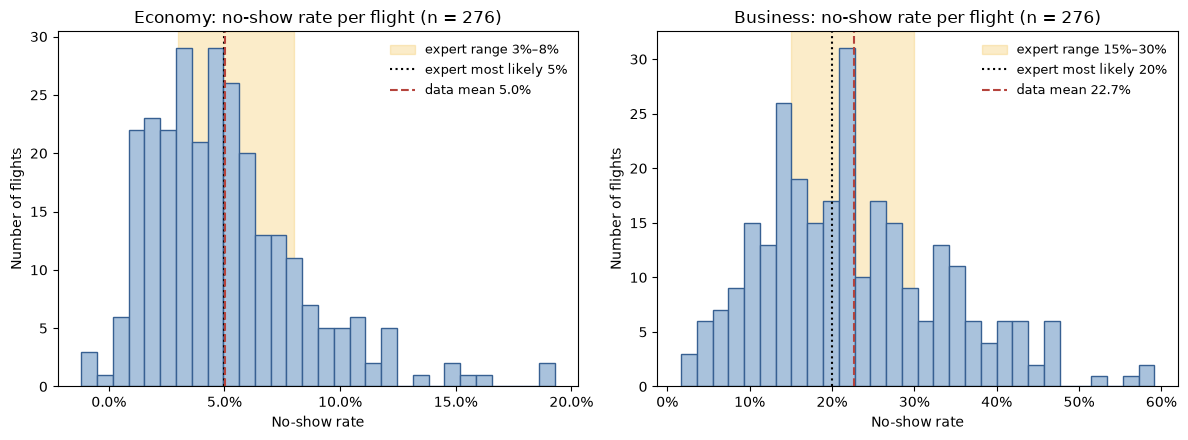

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
titles = {"econ_noshow_rate": "Economy", "bus_noshow_rate": "Business"}

for ax, (column, (low, mode, high)) in zip(axes, EXPERT_RANGE.items()):
    rates = clean[column]
    ax.axvspan(low, high, color="#f2c14e", alpha=0.3, label=f"expert range {low:.0%}–{high:.0%}")
    ax.hist(rates, bins=30, color="#a9c2dc", edgecolor="#376092")
    ax.axvline(mode, color="black", linestyle=":", label=f"expert most likely {mode:.0%}")
    ax.axvline(rates.mean(), color="#b5433c", linestyle="--", label=f"data mean {rates.mean():.1%}")
    ax.set_title(f"{titles[column]}: no-show rate per flight (n = {len(rates)})")
    ax.set_xlabel("No-show rate")
    ax.set_ylabel("Number of flights")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    ax.legend(frameon=False, fontsize=9)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "step3b-noshow-distribution.png", dpi=200, bbox_inches="tight")
plt.close(fig)
fig

### Weekly trend
Is the no-show rate stable over the 10 weeks, or drifting? Weeks run Monday to Sunday. The first and last weeks may be partial, so the number of flights per week is shown too.

In [11]:
weekly = clean.groupby("week").agg(
    flights=("flight_id", "count"),
    econ_mean=("econ_noshow_rate", "mean"),
    bus_mean=("bus_noshow_rate", "mean"),
)
weekly.round(3)

,flights,econ_mean,bus_mean
week,,,
2025-10-27,8,0.035,0.336
2025-11-03,28,0.049,0.190
2025-11-10,28,0.046,0.205
2025-11-17,27,0.070,0.267
2025-11-24,27,0.015,0.365
2025-12-01,28,0.054,0.204
2025-12-08,28,0.054,0.208
2025-12-15,27,0.051,0.215
2025-12-22,27,0.042,0.179


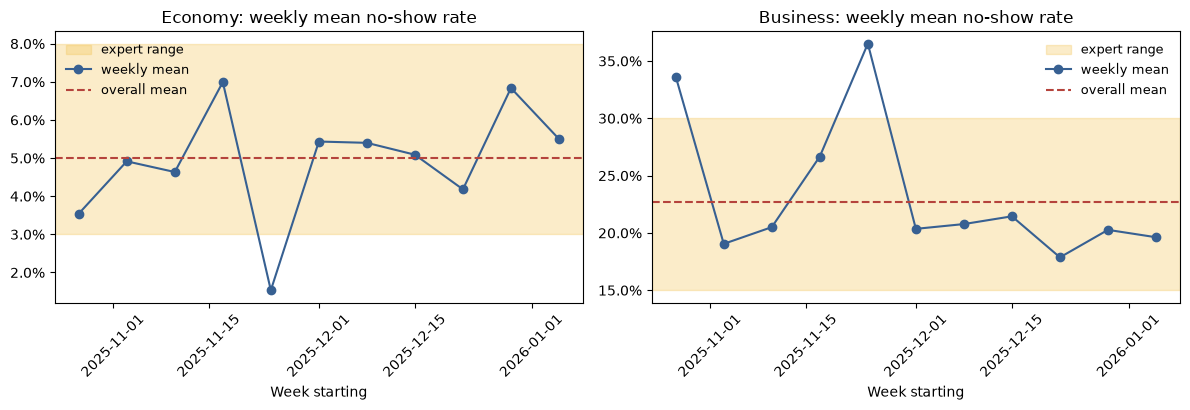

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

for ax, column, title in zip(axes, ["econ_mean", "bus_mean"], ["Economy", "Business"]):
    rate_column = "econ_noshow_rate" if column == "econ_mean" else "bus_noshow_rate"
    low, mode, high = EXPERT_RANGE[rate_column]
    ax.axhspan(low, high, color="#f2c14e", alpha=0.3, label="expert range")
    ax.plot(weekly.index, weekly[column], color="#376092", marker="o", label="weekly mean")
    ax.axhline(clean[rate_column].mean(), color="#b5433c", linestyle="--", label="overall mean")
    ax.set_title(f"{title}: weekly mean no-show rate")
    ax.set_xlabel("Week starting")
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    ax.tick_params(axis="x", rotation=45)
    ax.legend(frameon=False, fontsize=9)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "step3b-weekly-noshow.png", dpi=200, bbox_inches="tight")
plt.close(fig)
fig

### Means by weekday, weekend vs. weekday, and flight number
Groups are small (about 40 flights per weekday and 70 per flight number), so differences of a point or so may be noise. The standard deviation and count are shown to help judge that.

In [13]:
WEEKDAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

by_weekday = clean.groupby("weekday").agg(
    flights=("flight_id", "count"),
    econ_mean=("econ_noshow_rate", "mean"),
    econ_std=("econ_noshow_rate", "std"),
    bus_mean=("bus_noshow_rate", "mean"),
    bus_std=("bus_noshow_rate", "std"),
).reindex(WEEKDAY_ORDER)
by_weekday.round(3)

,flights,econ_mean,econ_std,bus_mean,bus_std
weekday,,,,,
Monday,39,0.053,0.031,0.193,0.104
Tuesday,39,0.038,0.025,0.213,0.089
Wednesday,38,0.056,0.045,0.233,0.124
Thursday,40,0.050,0.036,0.175,0.118
Friday,40,0.043,0.021,0.221,0.106
Saturday,40,0.054,0.031,0.268,0.109
Sunday,40,0.057,0.036,0.283,0.094


In [14]:
by_weekend = clean.groupby("is_weekend").agg(
    flights=("flight_id", "count"),
    econ_mean=("econ_noshow_rate", "mean"),
    econ_std=("econ_noshow_rate", "std"),
    bus_mean=("bus_noshow_rate", "mean"),
    bus_std=("bus_noshow_rate", "std"),
)
by_weekend.index = by_weekend.index.map({False: "weekday (Mon–Fri)", True: "weekend (Sat–Sun)"})
by_weekend.round(3)

,flights,econ_mean,econ_std,bus_mean,bus_std
is_weekend,,,,,
weekday (Mon–Fri),196,0.048,0.033,0.207,0.110
weekend (Sat–Sun),80,0.055,0.033,0.276,0.101


In [15]:
by_flight = clean.groupby("flight_number").agg(
    flights=("flight_id", "count"),
    econ_mean=("econ_noshow_rate", "mean"),
    econ_std=("econ_noshow_rate", "std"),
    bus_mean=("bus_noshow_rate", "mean"),
    bus_std=("bus_noshow_rate", "std"),
)
by_flight.round(3)

,flights,econ_mean,econ_std,bus_mean,bus_std
flight_number,,,,,
TA101,68,0.049,0.031,0.230,0.112
TA102,70,0.052,0.031,0.221,0.109
TA103,70,0.054,0.038,0.228,0.116
TA104,68,0.046,0.031,0.228,0.111


### Correlation between the classes
Do economy and business no-shows move together on the same flight? If they do, the model should not draw them independently.

In [16]:
pearson = clean["econ_noshow_rate"].corr(clean["bus_noshow_rate"], method="pearson")
spearman = clean["econ_noshow_rate"].corr(clean["bus_noshow_rate"], method="spearman")
print(f"Correlation between economy and business no-show rates on the same flight (n = {len(clean)}):")
print(f"  Pearson:  {pearson:.3f}")
print(f"  Spearman: {spearman:.3f}")

Correlation between economy and business no-show rates on the same flight (n = 276):
  Pearson:  0.065
  Spearman: -0.014


**What the near-zero correlation hides.** Over all 276 flights the correlation is about 0, but that comes from two outlier periods pulling in opposite directions:

- **Thanksgiving week (24–30 Nov)** pushes the cabins *apart*: economy no-shows almost disappear (~1.5%) while business jumps (~36%).
- **19–20 Nov**, around the weather diversion, pushes them *together*: both cabins are high at once (economy 12–14%, business 40–45%).

| Sample (checked outside this notebook) | Pearson |
|---|---|
| All flights | 0.07 |
| Excluding Thanksgiving week | 0.25 |
| Excluding 19–20 Nov | −0.07 |
| Excluding both | 0.12 (p ≈ 0.07) |

So the accurate reading is **weakly positive on normal days, with disruption days moving both cabins together**. It is not "independent". Disruption days are exactly the ones that drive bumping risk, so the simulation should be run with independent cabins *and* with a mild positive correlation, as a sensitivity check.

## Step 4: How variable are no-shows, and what distribution should the model use?

Step 3b gave the average no-show rate. The simulation also needs to know how much the rate **varies from flight to flight**, and how precisely we know the average.

- **Dispersion ratio.** If every passenger no-shows independently with the same probability $q$, the per-flight rate has binomial variance $q(1-q)/n$ ($n$ = 420 or 120 booked). The ratio *observed variance ÷ binomial variance* is about 1 if a plain Binomial($B$, $q$) is enough. Well above 1 means the rate itself shifts from flight to flight, and a binomial model would understate bumping risk. The p-value tests ratio = 1 ($(k-1) \times$ ratio $\sim \chi^2_{k-1}$ for $k$ flights).
- **Beta fit (method of moments)** for the *underlying* per-flight rate $p$, so the simulation can draw $p \sim$ Beta($\alpha$, $\beta$) and then no-shows $\sim$ Binomial($B$, $p$). The observed rate already contains binomial noise, so that part is removed first: $\operatorname{Var}(p) = \big(\text{observed variance} - m(1-m)/n\big) / (1 - 1/n)$. Then $\alpha + \beta = m(1-m)/\operatorname{Var}(p) - 1$, with $\alpha = m(\alpha+\beta)$.
- **Bootstrap 95% CI for the mean rate**, 10,000 resamples. Resampling individual flights treats them as independent. Step 3b showed that flights on the same day move together, so a second CI resamples **whole days**. That is the more honest one.
- **Ordinary days** exclude the two disruption periods found in Step 3b: 19–20 Nov (weather) and Thanksgiving week (24–30 Nov). That leaves the pattern on a typical day; the all-flights rows keep the disruptions in.
- **Business by weekday vs. weekend**, because Step 3b showed business no-shows are clearly higher on Saturdays and Sundays.

The expert triangular distributions (3%, 5%, 8%) and (15%, 20%, 30%) sit in the same table for comparison: mean, SD and 5th/95th percentiles.

In [17]:
from scipy import stats

# Disruption periods identified in Step 3b
DISRUPTED_DAYS = pd.date_range("2025-11-19", "2025-11-20").union(pd.date_range("2025-11-24", "2025-11-30"))
clean["is_ordinary_day"] = ~clean["date"].isin(DISRUPTED_DAYS)
ordinary = clean[clean["is_ordinary_day"]]

print(f"All flights:          {len(clean)} flights on {clean['date'].nunique()} days")
print(f"Ordinary days only:   {len(ordinary)} flights on {ordinary['date'].nunique()} days")
print(f"Excluded as disrupted: {len(clean) - len(ordinary)} flights on {len(DISRUPTED_DAYS)} days")

All flights:          276 flights on 70 days
Ordinary days only:   242 flights on 61 days
Excluded as disrupted: 34 flights on 9 days


In [18]:
RATE_COLUMNS = {
    "economy": ("econ_noshow_rate", "economy_booked"),
    "business": ("bus_noshow_rate", "business_booked"),
}
N_BOOT = 10_000
rng = np.random.default_rng(2026)


def flight_bootstrap_ci(rates):
    resamples = rng.choice(rates, size=(N_BOOT, len(rates)), replace=True)
    return np.quantile(resamples.mean(axis=1), [0.025, 0.975])


def day_bootstrap_ci(flights, rate_column):
    # Resample whole days, then average over all flights on the drawn days
    daily = flights.groupby("date")[rate_column].agg(["sum", "count"])
    picks = rng.integers(0, len(daily), size=(N_BOOT, len(daily)))
    means = daily["sum"].to_numpy()[picks].sum(axis=1) / daily["count"].to_numpy()[picks].sum(axis=1)
    return np.quantile(means, [0.025, 0.975])


def describe_rates(flights, cabin):
    rate_column, booked_column = RATE_COLUMNS[cabin]
    rates = flights[rate_column].to_numpy()
    n_booked = flights[booked_column].mean()  # 420 / 120 on every flight
    flight_count = len(rates)

    mean = rates.mean()
    observed_var = rates.var(ddof=1)
    binomial_var = mean * (1 - mean) / n_booked
    dispersion = observed_var / binomial_var
    p_value = stats.chi2.sf((flight_count - 1) * dispersion, flight_count - 1)

    # Beta for the underlying rate, after removing the binomial noise
    latent_var = (observed_var - binomial_var) / (1 - 1 / n_booked)
    if latent_var > 0:
        concentration = mean * (1 - mean) / latent_var - 1
        alpha, beta = mean * concentration, (1 - mean) * concentration
        beta_sd = stats.beta.std(alpha, beta)
        beta_p5, beta_p95 = stats.beta.ppf([0.05, 0.95], alpha, beta)
    else:
        alpha = beta = beta_sd = beta_p5 = beta_p95 = np.nan  # no extra-binomial variation to fit

    flight_low, flight_high = flight_bootstrap_ci(rates)
    day_low, day_high = day_bootstrap_ci(flights, rate_column)

    return {
        "flights": flight_count,
        "mean": mean,
        "CI low (flights)": flight_low,
        "CI high (flights)": flight_high,
        "CI low (days)": day_low,
        "CI high (days)": day_high,
        "observed SD": np.sqrt(observed_var),
        "binomial SD": np.sqrt(binomial_var),
        "dispersion ratio": dispersion,
        "p-value (ratio = 1)": p_value,
        "beta alpha": alpha,
        "beta beta": beta,
        "SD": beta_sd,
        "p5": beta_p5,
        "p95": beta_p95,
    }


def describe_triangular(low, mode, high):
    triangular = stats.triang(c=(mode - low) / (high - low), loc=low, scale=high - low)
    return {
        "mean": triangular.mean(),
        "SD": triangular.std(),
        "p5": triangular.ppf(0.05),
        "p95": triangular.ppf(0.95),
    }

In [19]:
weekday_flights = clean[~clean["is_weekend"]]
weekend_flights = clean[clean["is_weekend"]]
ordinary_weekday = ordinary[~ordinary["is_weekend"]]
ordinary_weekend = ordinary[ordinary["is_weekend"]]

SAMPLES = [
    ("economy", "all flights", clean),
    ("economy", "ordinary days", ordinary),
    ("business", "all flights", clean),
    ("business", "ordinary days", ordinary),
    ("business", "weekday (Mon–Fri), all", weekday_flights),
    ("business", "weekend (Sat–Sun), all", weekend_flights),
    ("business", "weekday (Mon–Fri), ordinary", ordinary_weekday),
    ("business", "weekend (Sat–Sun), ordinary", ordinary_weekend),
]

table_rows = []
for cabin in ["economy", "business"]:
    low, mode, high = EXPERT_RANGE[RATE_COLUMNS[cabin][0]]
    expert_row = describe_triangular(low, mode, high)
    expert_row.update({"class": cabin, "sample": f"expert triangular ({low:.0%}, {mode:.0%}, {high:.0%})"})
    table_rows.append(expert_row)

    for sample_cabin, sample_name, flights in SAMPLES:
        if sample_cabin == cabin:
            row = describe_rates(flights, cabin)
            row.update({"class": cabin, "sample": sample_name})
            table_rows.append(row)

noshow_distributions = pd.DataFrame(table_rows).set_index(["class", "sample"])
noshow_distributions = noshow_distributions[[
    "flights", "mean", "CI low (flights)", "CI high (flights)", "CI low (days)", "CI high (days)",
    "observed SD", "binomial SD", "dispersion ratio", "p-value (ratio = 1)",
    "beta alpha", "beta beta", "SD", "p5", "p95",
]]

percent_columns = ["mean", "CI low (flights)", "CI high (flights)", "CI low (days)", "CI high (days)",
                   "observed SD", "binomial SD", "SD", "p5", "p95"]
noshow_distributions.style.format("{:.1%}", subset=percent_columns, na_rep="") \
    .format("{:.0f}", subset=["flights"], na_rep="") \
    .format("{:.1f}", subset=["dispersion ratio", "beta alpha", "beta beta"], na_rep="") \
    .format(lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}", subset=["p-value (ratio = 1)"], na_rep="")

**Reading the table.** *SD*, *p5* and *p95* describe the per-flight rate: from the fitted beta for the data rows, and from the triangular distribution for the expert rows. *Observed SD* is the raw spread of the logged rates, which includes binomial noise.

**What it shows**
- **The means agree with the experts.** Economy is about 5.0–5.2% against an expert mean of 5.3%. Business is 20.6% on ordinary days (22.7% with the disruptions) against 21.7%. Even the day-level CIs are narrow, about ±0.5 points for economy and ±1.5–2 points for business. The *average* is not the big uncertainty.
- **A plain binomial is wrong for both classes.** The observed variance is 7–10 times the binomial variance, and still 5–7 times on ordinary days, so the excess is not just the disruptions. The rate itself moves from flight to flight. Binomial($B$, $q$) with a fixed $q$ would make bumping look much rarer than it is.
- **Per-flight spread is about three times wider than the expert triangle.** On ordinary days the beta fit gives economy 1.6–10.3% (5th–95th percentile) against the experts' 3.7–7.1%, and business 7.6–37% against 17–27%. The experts' ranges are a fair guess at the *mean* rate. They are far too narrow as a *per-flight* distribution.
- **Business weekends are a different population.** The ordinary-day mean is 18.2% on weekdays and 26.1% on weekends, and the day-level CIs (16.7–19.8% vs. 24.1–28.2%) don't overlap. A single business limit would be too tight on weekends or too loose on weekdays, so a day-of-week limit is worth testing.

**For the simulation:** draw the per-flight rate from the ordinary-day beta, e.g. economy Beta(3.4, 62.2) and business Beta(3.8, 17.2) weekdays / Beta(6.8, 19.3) weekends, then draw no-shows ~ Binomial($B$, rate). Disruption days need to be handled separately (a scenario, or a mixture with their frequency of about 9 days in 70) rather than averaged in.


## Step 5: Reproduce the £6,250, then build the simulation

### 5a. The predecessor's deterministic cost
The predecessor put the most likely no-show rates (5% economy, 20% business) into the booking limits and costed the **expected** show-ups as if they were certain:

- Economy: 420 × 95% = 399 show up, leaving 1 empty seat × £450 = £450
- Business: 120 × 80% = 96 show up, leaving 4 empty seats × £1,450 = £5,800

No one is bumped in either class, so the total is £6,250. The model function below is the cost model used for the rest of the notebook, with the deterministic show-ups plugged in.

In [20]:
from decision_suite.sim import Model, Parameter, triangular


def flight_cost(economy_limit, business_limit, economy_noshow_rate, business_noshow_rate,
                economy_capacity, business_capacity, economy_fare, business_fare,
                economy_bump_cost, business_bump_cost):
    economy_shows = economy_limit * (1 - economy_noshow_rate)
    business_shows = business_limit * (1 - business_noshow_rate)

    economy_empty = max(economy_capacity - economy_shows, 0)
    economy_bumped = max(economy_shows - economy_capacity, 0)
    business_empty = max(business_capacity - business_shows, 0)
    business_bumped = max(business_shows - business_capacity, 0)

    economy_cost = economy_fare * economy_empty + economy_bump_cost * economy_bumped
    business_cost = business_fare * business_empty + business_bump_cost * business_bumped
    return {
        "economy_shows": economy_shows,
        "economy_empty": economy_empty,
        "economy_bumped": economy_bumped,
        "economy_cost": economy_cost,
        "business_shows": business_shows,
        "business_empty": business_empty,
        "business_bumped": business_bumped,
        "business_cost": business_cost,
        "total_cost": economy_cost + business_cost,
    }


model = Model(flight_cost, parameters={
    "economy_limit": 420,
    "business_limit": 120,
    "economy_noshow_rate": Parameter(name="economy_noshow_rate", base=0.05, low=0.03, high=0.08,
                                     distribution=triangular(0.03, 0.05, 0.08),
                                     description="expert judgement"),
    "business_noshow_rate": Parameter(name="business_noshow_rate", base=0.20, low=0.15, high=0.30,
                                      distribution=triangular(0.15, 0.20, 0.30),
                                      description="expert judgement"),
    "economy_capacity": 400,
    "business_capacity": 100,
    "economy_fare": 450,
    "business_fare": 1450,
    "economy_bump_cost": 150,
    "business_bump_cost": 300,
}, objective="total_cost")

predecessor = model.run()
print(f"Predecessor's deterministic cost per flight: £{predecessor.objective:,.0f}")
predecessor

Predecessor's deterministic cost per flight: £6,250


economy_shows,399.00
economy_empty,1.00
economy_bumped,0.00
economy_cost,450.00
business_shows,96.00
business_empty,4.00
business_bumped,0.00
business_cost,"5,800.00"
total_cost,"6,250.00"


### 5b. Two-level Monte Carlo

**Outer loop (epistemic): what is the true mean no-show rate?** 1,000 draws of the pair ($q_E$, $q_B$) from either:
- **Expert:** the triangular distributions (3%, 5%, 8%) and (15%, 20%, 30%), drawn independently, or
- **Data:** the day-level bootstrap of the ordinary-day mean from Step 4. Each draw resamples the 61 ordinary days and takes the mean over their flights, which keeps any link between the two cabins' means.

**Inner loop (aleatoric): what happens on each flight?** 2,000 flights per outer draw (500 days × 4 flights). Each flight's no-show rate is drawn from Beta with mean $q$ and the **ordinary-day concentration** $\alpha + \beta$ fitted in Step 4. Show-ups are then Binomial($B$, 1 − rate), which is the beta-binomial. **Assumption:** the expert inputs use the same flight-to-flight spread as the data, because the experts only gave a range for the mean. This way the two input sources differ only in the mean.

**Correlation between cabins** is set through a day-level factor shared by the 4 flights of a day. It enters a Gaussian copula, so each cabin's beta marginal stays exactly as above:
| Setting | Economy rate | Business rate | Cabin correlation (latent) |
|---|---|---|---|
| Independent (base case) | own noise only | own noise only | 0 |
| Common shock | + day factor | + day factor | +0.4 |
| Divergent (Thanksgiving-type) | − day factor | + day factor | −0.4 |

The ±0.4 is a stress assumption, not an estimate. The flight-level correlation was 0.12–0.25 on normal days in Step 3b, and disruption days push it further in either direction.

**Common random numbers.** Every random number (outer draws, day factors, per-flight noise, show-up uniforms) is drawn once and reused for every booking limit, input source and correlation setting. Show-ups for the first $C$ bookings (400 / 100) come from the binomial inverse CDF of a fixed uniform. Each booking above capacity then gets its own fixed coin flip: booking number 421 is the same simulated passenger, who shows or doesn't, at every limit from 421 upwards. So a higher limit never gives fewer show-ups on the same simulated flight, and a sweep over limits (Step 6) only adds one coin flip per extra booking. Differences between policies are then due to the policy, not to simulation noise.

In [21]:
from decision_suite.sim import Triangular

N_OUTER = 1_000
DAYS_PER_OUTER = 500
FLIGHTS_PER_DAY = 4
CORRELATION_SETTINGS = {
    "independent": {"rho": 0.0, "economy_sign": 1},
    "common shock": {"rho": 0.4, "economy_sign": 1},
    "divergent": {"rho": 0.4, "economy_sign": -1},
}
EXPERT_TRIANGULAR = {
    "economy": Triangular(0.03, 0.05, 0.08),
    "business": Triangular(0.15, 0.20, 0.30),
}
CONCENTRATION = {}
for cabin in ["economy", "business"]:
    fitted = noshow_distributions.loc[(cabin, "ordinary days")]
    CONCENTRATION[cabin] = fitted["beta alpha"] + fitted["beta beta"]
print(f"Beta concentration (alpha + beta), ordinary days: economy {CONCENTRATION['economy']:.1f}, "
      f"business {CONCENTRATION['business']:.1f}")

# Common random numbers: drawn once, reused for every policy, input source and correlation setting
crn = np.random.default_rng(2026)
shape = (N_OUTER, DAYS_PER_OUTER, FLIGHTS_PER_DAY)
CRN = {
    "outer_uniform_economy": crn.random(N_OUTER),
    "outer_uniform_business": crn.random(N_OUTER),
    "bootstrap_days": crn.integers(0, ordinary["date"].nunique(), size=(N_OUTER, ordinary["date"].nunique())),
    "day_factor": crn.standard_normal((N_OUTER, DAYS_PER_OUTER, 1)),
    "economy_noise": crn.standard_normal(shape),
    "business_noise": crn.standard_normal(shape),
    "economy_show_uniform": crn.random(shape),
    "business_show_uniform": crn.random(shape),
}

Beta concentration (alpha + beta), ordinary days: economy 65.6, business 19.0


In [22]:
def outer_means(source):
    # One (economy, business) mean no-show rate per outer draw
    if source == "expert":
        economy = EXPERT_TRIANGULAR["economy"].ppf(CRN["outer_uniform_economy"])
        business = EXPERT_TRIANGULAR["business"].ppf(CRN["outer_uniform_business"])
        return economy, business

    daily = ordinary.groupby("date").agg(
        economy_sum=("econ_noshow_rate", "sum"),
        business_sum=("bus_noshow_rate", "sum"),
        flights=("flight_id", "count"),
    )
    picks = CRN["bootstrap_days"]
    flights = daily["flights"].to_numpy()[picks].sum(axis=1)
    economy = daily["economy_sum"].to_numpy()[picks].sum(axis=1) / flights
    business = daily["business_sum"].to_numpy()[picks].sum(axis=1) / flights
    return economy, business


def flight_rates(source, setting):
    # Per-flight no-show rates: beta marginals around each outer mean, linked through a day-level factor
    economy_mean, business_mean = outer_means(source)
    rho = CORRELATION_SETTINGS[setting]["rho"]
    sign = CORRELATION_SETTINGS[setting]["economy_sign"]
    loading = np.sqrt(rho)
    own = np.sqrt(1 - rho)

    economy_z = sign * loading * CRN["day_factor"] + own * CRN["economy_noise"]
    business_z = loading * CRN["day_factor"] + own * CRN["business_noise"]

    rates = {}
    for cabin, mean, z in [("economy", economy_mean, economy_z), ("business", business_mean, business_z)]:
        mean = mean[:, None, None]
        kappa = CONCENTRATION[cabin]
        rates[cabin] = stats.beta.ppf(stats.norm.cdf(z), mean * kappa, (1 - mean) * kappa)
    return rates


def extra_booking_uniform(cabin, booking_number):
    # One fixed uniform per simulated flight for each booking above capacity, the same at every limit
    cabin_index = 0 if cabin == "economy" else 1
    return np.random.default_rng([2026, cabin_index, booking_number]).random(shape)


def cabin_shows(cabin, limit, rate, capacity):
    # Booking limits are at least capacity (Step 1): the first `capacity` bookings, then one coin flip per extra booking
    shows = stats.binom.ppf(CRN[f"{cabin}_show_uniform"], capacity, 1 - rate)
    for booking_number in range(capacity + 1, limit + 1):
        shows = shows + (extra_booking_uniform(cabin, booking_number) >= rate)
    return shows


def simulate_policy(economy_limit, business_limit, rates, params=None):
    # Cost of every simulated flight for one pair of booking limits, using the shared random numbers
    if params is None:
        params = model.base_values()
    economy_shows = cabin_shows("economy", economy_limit, rates["economy"], params["economy_capacity"])
    business_shows = cabin_shows("business", business_limit, rates["business"], params["business_capacity"])

    economy_empty = np.maximum(params["economy_capacity"] - economy_shows, 0)
    economy_bumped = np.maximum(economy_shows - params["economy_capacity"], 0)
    business_empty = np.maximum(params["business_capacity"] - business_shows, 0)
    business_bumped = np.maximum(business_shows - params["business_capacity"], 0)

    total_cost = (params["economy_fare"] * economy_empty + params["economy_bump_cost"] * economy_bumped
                  + params["business_fare"] * business_empty + params["business_bump_cost"] * business_bumped)
    return {
        "total_cost": total_cost,
        "economy_bumped": economy_bumped,
        "business_bumped": business_bumped,
    }


def summarise(simulated):
    cost = simulated["total_cost"].ravel()
    p95 = np.quantile(cost, 0.95)
    outer_mean_cost = simulated["total_cost"].mean(axis=(1, 2))  # expected cost under each outer draw
    any_bump = (simulated["economy_bumped"] > 0) | (simulated["business_bumped"] > 0)
    return {
        "mean cost": cost.mean(),
        "SD": cost.std(),
        "P95": p95,
        "CVaR95": cost[cost >= p95].mean(),
        "P(any bump)": any_bump.mean(),
        "P(business bump)": (simulated["business_bumped"] > 0).mean(),
        "expected bumps, economy": simulated["economy_bumped"].mean(),
        "expected bumps, business": simulated["business_bumped"].mean(),
        "90% band low (mean cost)": np.quantile(outer_mean_cost, 0.05),
        "90% band high (mean cost)": np.quantile(outer_mean_cost, 0.95),
    }

In [23]:
FLIGHT_RATES = {}
for source in ["expert", "data"]:
    for setting in CORRELATION_SETTINGS:
        FLIGHT_RATES[(source, setting)] = flight_rates(source, setting)

current_policy = {}
summary_rows = []
for (source, setting), rates in FLIGHT_RATES.items():
    simulated = simulate_policy(420, 120, rates)
    current_policy[(source, setting)] = simulated
    row = summarise(simulated)
    row.update({"inputs": source, "correlation": setting})
    summary_rows.append(row)

current_summary = pd.DataFrame(summary_rows).set_index(["inputs", "correlation"])
money_columns = ["mean cost", "SD", "P95", "CVaR95", "90% band low (mean cost)", "90% band high (mean cost)"]
current_summary.style.format("£{:,.0f}", subset=money_columns) \
    .format("{:.1%}", subset=["P(any bump)", "P(business bump)"]) \
    .format("{:.2f}", subset=["expected bumps, economy", "expected bumps, business"])

### Cost distribution under the current policy (420 / 120)
Independent cabins, expert vs. data inputs. Every simulated flight from every outer draw is included. The black line is the predecessor's £6,250, and the dashed lines are the simulated means.

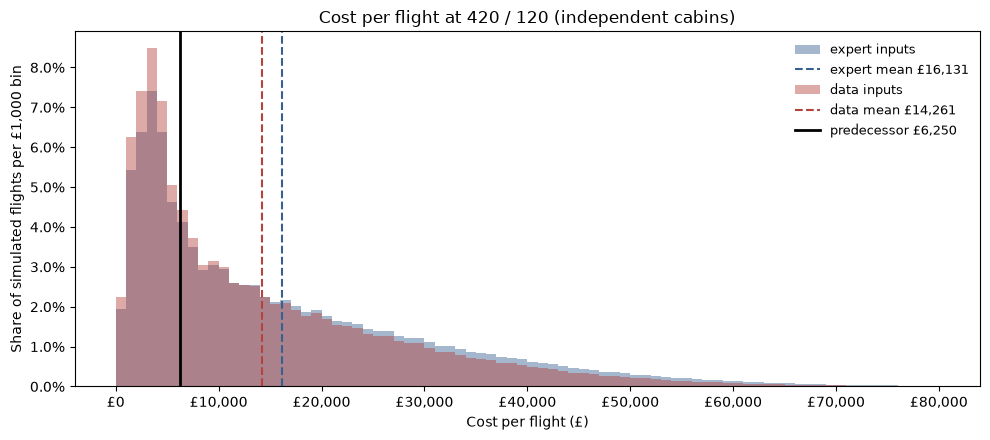

In [24]:
fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.arange(0, 80_001, 1_000)
colors = {"expert": "#376092", "data": "#b5433c"}

for source in ["expert", "data"]:
    cost = current_policy[(source, "independent")]["total_cost"].ravel()
    weights = np.full(len(cost), 1 / len(cost))
    ax.hist(cost, bins=bins, weights=weights, alpha=0.45, color=colors[source], label=f"{source} inputs")
    ax.axvline(cost.mean(), color=colors[source], linestyle="--", label=f"{source} mean £{cost.mean():,.0f}")

ax.axvline(predecessor.objective, color="black", linewidth=2, label=f"predecessor £{predecessor.objective:,.0f}")
ax.set_title("Cost per flight at 420 / 120 (independent cabins)")
ax.set_xlabel("Cost per flight (£)")
ax.set_ylabel("Share of simulated flights per £1,000 bin")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("£{x:,.0f}"))
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "step5-cost-distribution-current.png", dpi=200, bbox_inches="tight")
plt.close(fig)
fig

### Check: what did the logged flights actually cost?
Every logged flight was flown at 420 / 120, and `*_boarded` is taken as show-ups (Step 3), so the actual cost of each flight can be computed directly. The **data / independent** simulation should land close to the ordinary-day figure.

In [25]:
actual_rows = []
for sample_name, flights in [("all flights", clean), ("ordinary days", ordinary)]:
    costs = []
    any_bump = []
    business_bump = []
    for economy_shows, business_shows in zip(flights["economy_boarded"], flights["business_boarded"]):
        # A no-show rate of 1 - shows/limit makes flight_cost use the logged show-ups
        outcome = flight_cost(420, 120, 1 - economy_shows / 420, 1 - business_shows / 120,
                              400, 100, 450, 1450, 150, 300)
        costs.append(outcome["total_cost"])
        any_bump.append(outcome["economy_bumped"] > 0 or outcome["business_bumped"] > 0)
        business_bump.append(outcome["business_bumped"] > 0)
    costs = np.array(costs)
    actual_rows.append({
        "sample": f"actual, {sample_name}",
        "flights": len(costs),
        "mean cost": costs.mean(),
        "SD": costs.std(),
        "P95": np.quantile(costs, 0.95),
        "P(any bump)": np.mean(any_bump),
        "P(business bump)": np.mean(business_bump),
    })

simulated_row = current_summary.loc[("data", "independent")]
actual_rows.append({
    "sample": "simulated, data / independent",
    "flights": N_OUTER * DAYS_PER_OUTER * FLIGHTS_PER_DAY,
    "mean cost": simulated_row["mean cost"],
    "SD": simulated_row["SD"],
    "P95": simulated_row["P95"],
    "P(any bump)": simulated_row["P(any bump)"],
    "P(business bump)": simulated_row["P(business bump)"],
})

actual_vs_simulated = pd.DataFrame(actual_rows).set_index("sample")
actual_vs_simulated.style.format("£{:,.0f}", subset=["mean cost", "SD", "P95"]) \
    .format("{:,.0f}", subset=["flights"]) \
    .format("{:.1%}", subset=["P(any bump)", "P(business bump)"])

,flights,mean cost,SD,P95,P(any bump),P(business bump)
sample,,,,,,
"actual, all flights",276,"£17,415","£16,945","£49,338",68.1%,33.3%
"actual, ordinary days",242,"£14,053","£13,591","£40,050",66.5%,38.0%
"simulated, data / independent","2,000,000","£14,261","£13,276","£41,550",68.2%,36.9%


### What Step 5 shows
- **The £6,250 is reproduced, and it is far too low.** The real expected cost at 420 / 120 is about **£14,300** with data inputs and **£16,100** with expert inputs, 2.3–2.6 times the predecessor's figure. The log confirms this: ordinary-day flights actually cost **£14,053** on average, and £17,415 including disruption days.
- **Why:** costing the *average* show-up hides the asymmetry. An empty business seat costs £1,450 and a business bump only £300, so the flights where more people than usual no-show cost far more than the flights where fewer do save. With the per-flight spread found in Step 4, business empty seats alone are worth about £10,000 per flight.
- **Bumping is routine, not rare.** About two-thirds of flights bump someone, and 34–37% bump at least one business passenger. On average that is about 3.8–3.9 economy and 2.3–2.5 business passengers bumped per flight. The deterministic model said zero.
- **The tail is heavy.** P95 is about £42–46k and CVaR95 about £51–56k per flight.
- **Expert vs. data:** the means are close, but the expert triangle leaves far more doubt about the true mean. The 90% band on expected cost is **£10.9k–£23.3k** for expert inputs and **£12.7k–£15.8k** for data inputs.
- **Correlation does not move the mean** (at £150 / £300 with no upgrades, the cabins are costed separately, so expected cost is additive). It moves the risk. A common shock raises the SD and P95 by about £1–2k and lowers P(any bump), because bad flights in the two cabins tend to fall on the same days. A divergent pattern does the opposite. This will matter once upgrades link the cabins (scenario S3).

**Next:** sweep the booking limits under these same random numbers to find the cost-minimising 420 / 120 replacement, and check how robust it is across the input sources and correlation settings.

## Step 6: Optimise the booking limits

Grid search over economy 400–460 × business 100–160 (61 × 61 = 3,721 policies), on the **same simulated flights** as Step 5, with independent cabins, for expert and for data inputs.

**How the grid is computed.** With no upgrades between cabins (the base case), a flight's cost is economy cost + business cost, and each depends only on its own limit. So each cabin's cost is simulated once per limit (61 + 61 runs), and the expected cost of every grid cell is the sum of the two. That gives exactly the same answer as simulating all 3,721 pairs. It also means the best economy limit does not depend on the business limit, and vice versa. If upgrades are modelled later (S3), this shortcut no longer holds and the grid has to be simulated jointly.

**Epistemic bands.** Each outer draw (a possible true mean no-show rate) gives its own expected cost curve. The band is the 5th–95th percentile of those curves. Because every limit uses the same simulated flights, the *saving* of one policy over another is computed draw by draw. Its band and P(saving > 0) are much tighter than the overlap of two cost bands would suggest.

In [26]:
ECONOMY_LIMITS = list(range(400, 461))
BUSINESS_LIMITS = list(range(100, 161))
FLIGHTS_PER_YEAR = 4 * 365


def cabin_cost_curve(cabin, rate, limits, params=None):
    # Expected cost of one cabin under each outer draw (rows) for each booking limit (columns)
    if params is None:
        params = model.base_values()
    capacity = params[f"{cabin}_capacity"]
    fare = params[f"{cabin}_fare"]
    bump_cost = params[f"{cabin}_bump_cost"]

    shows = cabin_shows(cabin, capacity, rate, capacity)
    booked = capacity
    curve = {}
    for limit in limits:
        while booked < limit:
            booked += 1
            shows = shows + (extra_booking_uniform(cabin, booked) >= rate)
        cost = fare * np.maximum(capacity - shows, 0) + bump_cost * np.maximum(shows - capacity, 0)
        curve[limit] = cost.mean(axis=(1, 2))
    return pd.DataFrame(curve)


CURVES = {}
for source in ["expert", "data"]:
    rates = FLIGHT_RATES[(source, "independent")]
    CURVES[(source, "economy")] = cabin_cost_curve("economy", rates["economy"], ECONOMY_LIMITS)
    CURVES[(source, "business")] = cabin_cost_curve("business", rates["business"], BUSINESS_LIMITS)

In [27]:
grids = {}
best_limits = {}
for source in ["expert", "data"]:
    economy_expected = CURVES[(source, "economy")].mean()
    business_expected = CURVES[(source, "business")].mean()
    grid = pd.DataFrame(
        business_expected.to_numpy()[None, :] + economy_expected.to_numpy()[:, None],
        index=pd.Index(ECONOMY_LIMITS, name="economy limit"),
        columns=pd.Index(BUSINESS_LIMITS, name="business limit"),
    )
    grids[source] = grid
    economy_best, business_best = grid.stack().idxmin()
    best_limits[source] = (economy_best, business_best)

    print(f"{source.upper()} inputs")
    print(f"  Best limits:     economy {economy_best}, business {business_best}   "
          f"expected cost £{grid.loc[economy_best, business_best]:,.0f} per flight")
    print(f"  Current 420/120: expected cost £{grid.loc[420, 120]:,.0f} per flight")
    edge = []
    if economy_best in (ECONOMY_LIMITS[0], ECONOMY_LIMITS[-1]):
        edge.append("economy")
    if business_best in (BUSINESS_LIMITS[0], BUSINESS_LIMITS[-1]):
        edge.append("business")
    if edge:
        print(f"  Warning: the best {' and '.join(edge)} limit is on the edge of the grid")
    print()

EXPERT inputs
  Best limits:     economy 430, business 142   expected cost £9,983 per flight
  Current 420/120: expected cost £16,131 per flight

DATA inputs
  Best limits:     economy 429, business 139   expected cost £9,223 per flight
  Current 420/120: expected cost £14,261 per flight



### How flat is the bottom?
The cost curves are flat near the minimum. The limits below keep each cabin's expected cost within £100 per flight (£146k a year) of its best. Choosing the **low end** of a range gives up almost nothing in expected cost and cuts bumping.

In [28]:
TOLERANCE = 100  # £ per flight

flat_rows = []
for source in ["expert", "data"]:
    for cabin in ["economy", "business"]:
        expected = CURVES[(source, cabin)].mean()
        near = expected[expected <= expected.min() + TOLERANCE]
        flat_rows.append({
            "inputs": source,
            "cabin": cabin,
            "best limit": expected.idxmin(),
            "near-optimal from": near.index.min(),
            "near-optimal to": near.index.max(),
            "best cabin cost": expected.min(),
        })

flat_bottom = pd.DataFrame(flat_rows).set_index(["inputs", "cabin"])
flat_bottom.style.format("£{:,.0f}", subset=["best cabin cost"])

### Cost curves with epistemic bands
Each panel shows one cabin's expected cost per flight (the other cabin's cost doesn't depend on this limit). Lines are the expected cost averaged over the outer draws. Shaded bands are the 5th–95th percentile across the outer draws, i.e. how much the curve moves with the true mean no-show rate. Dots mark the best limit and crosses the current one.

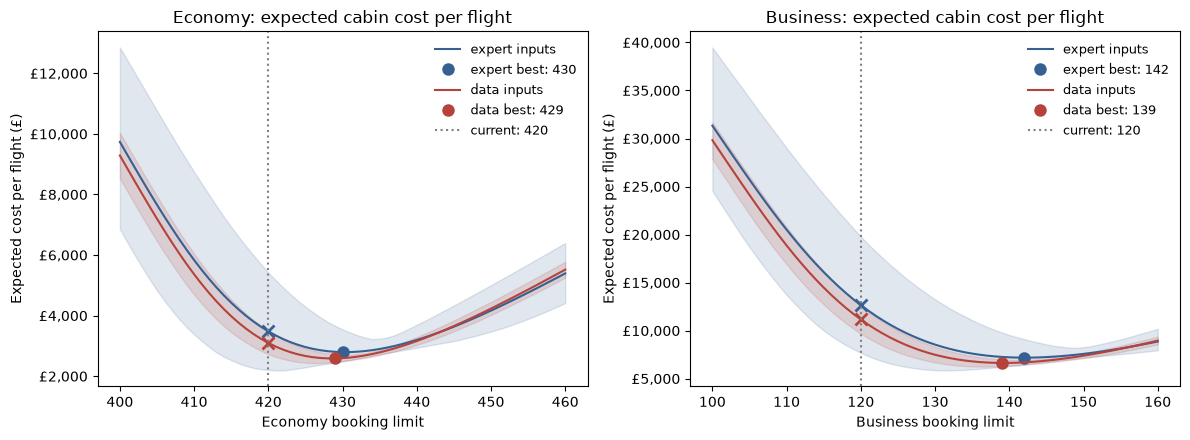

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colors = {"expert": "#376092", "data": "#b5433c"}
current_limit = {"economy": 420, "business": 120}

for ax, cabin in zip(axes, ["economy", "business"]):
    for source in ["expert", "data"]:
        curve = CURVES[(source, cabin)]
        limits = curve.columns.to_numpy()
        ax.fill_between(limits, curve.quantile(0.05), curve.quantile(0.95), color=colors[source], alpha=0.15)
        ax.plot(limits, curve.mean(), color=colors[source], label=f"{source} inputs")
        best = best_limits[source][0 if cabin == "economy" else 1]
        ax.plot(best, curve[best].mean(), "o", color=colors[source], markersize=8,
                label=f"{source} best: {best}")
        now = current_limit[cabin]
        ax.plot(now, curve[now].mean(), "x", color=colors[source], markersize=9, markeredgewidth=2)
    ax.axvline(current_limit[cabin], color="grey", linestyle=":", label=f"current: {current_limit[cabin]}")
    ax.set_title(f"{cabin.capitalize()}: expected cabin cost per flight")
    ax.set_xlabel(f"{cabin.capitalize()} booking limit")
    ax.set_ylabel("Expected cost per flight (£)")
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("£{x:,.0f}"))
    ax.legend(frameon=False, fontsize=9)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "step6-cost-curves.png", dpi=200, bbox_inches="tight")
plt.close(fig)
fig

### Best vs. current
Each policy is evaluated under both input sources, so the table also shows whether the limits chosen under one set of inputs still save money under the other. *Saving* is against 420 / 120 under the same inputs. It is computed per outer draw on the same flights: the 90% band is the 5th–95th percentile of the annual saving across draws, and P(saving > 0) is the share of draws where the policy beats 420 / 120. Annual figures are per flight × 4 flights × 365 days.

In [30]:
policies = {
    "current 420 / 120": (420, 120),
    f"best under expert {best_limits['expert'][0]} / {best_limits['expert'][1]}": best_limits["expert"],
    f"best under data {best_limits['data'][0]} / {best_limits['data'][1]}": best_limits["data"],
}

comparison_rows = []
for source in ["expert", "data"]:
    economy_curve = CURVES[(source, "economy")]
    business_curve = CURVES[(source, "business")]
    current_per_draw = economy_curve[420] + business_curve[120]
    for policy_name, (economy_limit, business_limit) in policies.items():
        per_draw = economy_curve[economy_limit] + business_curve[business_limit]
        annual_saving = (current_per_draw - per_draw) * FLIGHTS_PER_YEAR
        risk = summarise(simulate_policy(economy_limit, business_limit, FLIGHT_RATES[(source, "independent")]))
        comparison_rows.append({
            "inputs": source,
            "policy": policy_name,
            "cost per flight": per_draw.mean(),
            "annual cost": per_draw.mean() * FLIGHTS_PER_YEAR,
            "annual saving": annual_saving.mean(),
            "saving 90% low": annual_saving.quantile(0.05),
            "saving 90% high": annual_saving.quantile(0.95),
            "P(saving > 0)": (annual_saving > 0).mean(),
            "P95 per flight": risk["P95"],
            "P(any bump)": risk["P(any bump)"],
            "P(business bump)": risk["P(business bump)"],
            "bumps per flight": risk["expected bumps, economy"] + risk["expected bumps, business"],
        })

best_vs_current = pd.DataFrame(comparison_rows).set_index(["inputs", "policy"])
money_columns = ["cost per flight", "annual cost", "annual saving", "saving 90% low", "saving 90% high",
                 "P95 per flight"]
best_vs_current.style.format("£{:,.0f}", subset=money_columns) \
    .format("{:.1%}", subset=["P(saving > 0)", "P(any bump)", "P(business bump)"]) \
    .format("{:.2f}", subset=["bumps per flight"])

### Separate weekday and weekend business limits
Step 4 found that the business no-show rate is clearly higher at weekends (ordinary days: 18.2% weekdays vs. 26.1% weekends). This test uses **data inputs only**, since the experts gave no weekday/weekend split:
- Outer draws bootstrap the weekday and weekend ordinary days separately, giving a weekday and a weekend mean for each draw.
- Each day type uses its own ordinary-day beta concentration from Step 4.
- The same simulated flights are run once as weekday flights and once as weekend flights. Weekdays are weighted 5/7 and weekends 2/7.

The comparison is **split limits vs. the best single business limit under this same model**, so the gain is due only to splitting.

In [31]:
DAY_TYPES = {
    "weekday": {"flights": ordinary[~ordinary["is_weekend"]], "weight": 5 / 7,
                "sample": "weekday (Mon–Fri), ordinary"},
    "weekend": {"flights": ordinary[ordinary["is_weekend"]], "weight": 2 / 7,
                "sample": "weekend (Sat–Sun), ordinary"},
}

split_rng = np.random.default_rng(2027)  # separate stream, so Step 5's random numbers are unchanged
day_type_curves = {}
for day_type, spec in DAY_TYPES.items():
    daily = spec["flights"].groupby("date").agg(
        business_sum=("bus_noshow_rate", "sum"),
        flights=("flight_id", "count"),
    )
    picks = split_rng.integers(0, len(daily), size=(N_OUTER, len(daily)))
    mean = daily["business_sum"].to_numpy()[picks].sum(axis=1) / daily["flights"].to_numpy()[picks].sum(axis=1)

    fitted = noshow_distributions.loc[("business", spec["sample"])]
    kappa = fitted["beta alpha"] + fitted["beta beta"]
    mean = mean[:, None, None]
    rate = stats.beta.ppf(stats.norm.cdf(CRN["business_noise"]), mean * kappa, (1 - mean) * kappa)
    day_type_curves[day_type] = cabin_cost_curve("business", rate, BUSINESS_LIMITS)

weekday_curve = day_type_curves["weekday"]
weekend_curve = day_type_curves["weekend"]
weekday_weight = DAY_TYPES["weekday"]["weight"]
weekend_weight = DAY_TYPES["weekend"]["weight"]

single_curve = weekday_weight * weekday_curve + weekend_weight * weekend_curve
single_best = single_curve.mean().idxmin()
weekday_best = weekday_curve.mean().idxmin()
weekend_best = weekend_curve.mean().idxmin()

single_per_draw = single_curve[single_best]
split_per_draw = weekday_weight * weekday_curve[weekday_best] + weekend_weight * weekend_curve[weekend_best]
current_per_draw = single_curve[120]
split_gain = (single_per_draw - split_per_draw) * FLIGHTS_PER_YEAR

split_rows = []
for policy_name, per_draw in [
    ("current 120 every day", current_per_draw),
    (f"single best {single_best} every day", single_per_draw),
    (f"split: {weekday_best} weekdays / {weekend_best} weekends", split_per_draw),
]:
    split_rows.append({
        "business policy": policy_name,
        "business cost per flight": per_draw.mean(),
        "annual business cost": per_draw.mean() * FLIGHTS_PER_YEAR,
    })
split_table = pd.DataFrame(split_rows).set_index("business policy")

print(f"Annual gain of splitting over the best single limit: £{split_gain.mean():,.0f}  "
      f"(90% band £{split_gain.quantile(0.05):,.0f} to £{split_gain.quantile(0.95):,.0f}, "
      f"P(gain > 0) = {(split_gain > 0).mean():.1%})")
print(f"As a share of the annual business cost under the single best limit: "
      f"{split_gain.mean() / (single_per_draw.mean() * FLIGHTS_PER_YEAR):.1%}")
split_table.style.format("£{:,.0f}")

Annual gain of splitting over the best single limit: £717,457  (90% band £308,721 to £1,148,546, P(gain > 0) = 100.0%)
As a share of the annual business cost under the single best limit: 7.5%


,business cost per flight,annual business cost
business policy,,
current 120 every day,"£11,125","£16,242,065"
single best 139 every day,"£6,588","£9,618,562"
split: 134 weekdays / 150 weekends,"£6,097","£8,901,105"


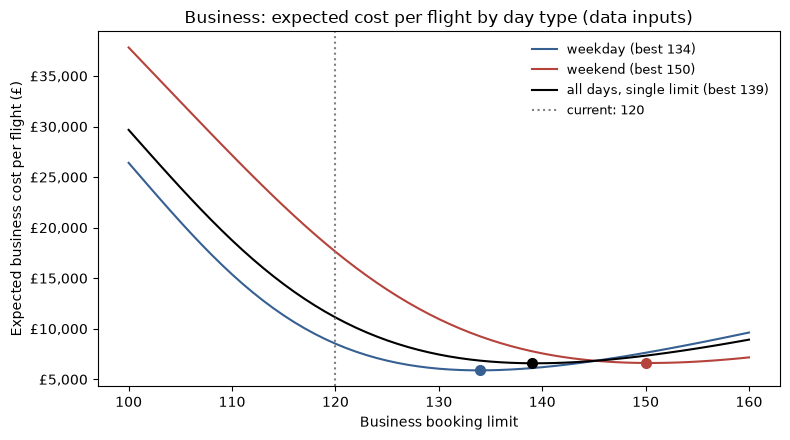

In [32]:
fig, ax = plt.subplots(figsize=(8, 4.5))
lines = [
    ("weekday", weekday_curve, "#376092", weekday_best),
    ("weekend", weekend_curve, "#b5433c", weekend_best),
    ("all days, single limit", single_curve, "black", single_best),
]
for label, curve, color, best in lines:
    ax.plot(curve.columns, curve.mean(), color=color, label=f"{label} (best {best})")
    ax.plot(best, curve[best].mean(), "o", color=color, markersize=7)
ax.axvline(120, color="grey", linestyle=":", label="current: 120")
ax.set_title("Business: expected cost per flight by day type (data inputs)")
ax.set_xlabel("Business booking limit")
ax.set_ylabel("Expected business cost per flight (£)")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("£{x:,.0f}"))
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "step6-business-weekday-weekend.png", dpi=200, bbox_inches="tight")
plt.close(fig)
fig

### What Step 6 shows
- **Best limits: economy 429–430, business 139–142.** Data inputs give **429 / 139** and expert inputs **430 / 142**. Both are well above the current 420 / 120, and neither is at the edge of the grid.
- **The choice is robust to which inputs you trust.** Each set of limits is within about £85 per flight of the other's optimum, whichever inputs are used to judge it. The flat bottom is wide: economy 425–434 and business 136–145 are all within £100 per flight of the best.
- **The saving is large and almost certain** at the base-case costs. With data inputs, the annual cost falls from **£20.8M to £13.5M**, a saving of **£7.4M a year** (90% band £5.5M–£9.2M, P(saving > 0) = 100%). With expert inputs the saving is £9.0M (90% band £2.3M–£16.6M, P = 99.7%). The wider band reflects the experts' wider range for the mean.
- **But it buys that saving with a lot of bumping.** About 22 passengers are bumped per flight (against about 6 today), and 78% of flights bump at least one business passenger (against 37%). This is what the model *should* do while a bump costs £150 / £300 against fares of £450 / £1,450, so it is only as good as those bump costs. At this scale, goodwill costs, the competitor's policy (S2) and a service-level cap on business bumps all need checking before any of these limits is recommended. It also assumes bookings fill to 139 business. The log can't show that, because bookings always hit the current 120 limit.

**Weekday / weekend business limits (data inputs).** The best split is **134 on weekdays and 150 at weekends**, against a best single limit of 139. It saves **£0.72M a year** over that single limit (90% band £0.31M–£1.15M, P(gain > 0) = 100%), which is 7.5% of the business cost. That is about a tenth of what re-optimising the single limits already gains.

**Is it worth the complexity?** On the numbers, yes. The gain is clearly positive in every outer draw, and the extra complexity is one more number in the booking system, which most airline systems already set by day of week. Two cautions:
- **Thin weekend data.** The weekend estimate rests on 72 flights (18 ordinary weekend days).
- **More weekend bumping.** The weekend limit of 150 makes the bumping problem above worse on exactly the days with the most business travellers.

So: adopt the single limits first, and add the weekend split once the bump-cost and service-level checks confirm that heavy business overbooking is acceptable.

## Step 7: Stress tests

Step 6 found limits of about **429 / 139** that save £7–9M a year at the base-case costs. This step checks how far that holds up:

- **7a. Bump cost:** the competitor's more generous bumping policy, as multiples of £150 / £300.
- **7b. Correlation:** the same policies with common-shock and divergent cabins, focusing on the tail.
- **7c. Upgrades:** bumped economy passengers moved into spare business seats, re-optimised jointly.
- **7d. Regret table:** five candidate policies against seven possible worlds.
- **7e. Sensitivity:** a tornado chart of which input moves the cost and the best limits most.

Everything runs on the **same simulated flights** (common random numbers) as Steps 5 and 6, so differences between policies and worlds are not simulation noise. The policy under test, called the *recommendation* below, is the Step 6 best on data inputs, 429 / 139.

### 7a. Bump cost: the competitor's policy

A more generous competitor raises what a bump costs us in goodwill, but by how much is unknown. So both bump costs are multiplied by 1, 1.5, 2, 3, 4 and 6 (×6 is £900 / £1,800).

**One sweep covers every multiplier.** A cabin's expected cost is fare × E[empty seats] + bump cost × E[bumped]. Neither expectation depends on the bump cost, so each cabin is swept once over the limits, and the cost curve for any multiplier is a weighted sum of the two. The first cell checks that multiplier 1 reproduces Step 6's curves exactly.

**Break-even.** The annual saving of a fixed policy over 420 / 120 is a straight line in the multiplier $m$: saving$(m) = a - m\,b$, where $a$ is the fare revenue recovered from fewer empty seats and $b$ is the extra bump cost at £150 / £300. The recommendation stops beating 420 / 120 at exactly $m^* = a / b$. Solving this per outer draw gives a 90% band for $m^*$.

In [33]:
BUMP_MULTIPLIERS = [1, 1.5, 2, 3, 4, 6]
RECOMMENDED = best_limits["data"]  # 429 / 139 from Step 6


def cabin_sweep(cabin, rate, limits, on_limit=None, params=None):
    # Expected empty seats and bumped passengers under each outer draw (rows) for each booking limit (columns).
    # on_limit(limit, flight_empty, flight_bumped), if given, sees every simulated flight at every limit (for upgrades)
    if params is None:
        params = model.base_values()
    capacity = params[f"{cabin}_capacity"]
    shows = cabin_shows(cabin, capacity, rate, capacity)
    booked = capacity
    empty, bumped = {}, {}
    for limit in limits:
        while booked < limit:
            booked += 1
            shows = shows + (extra_booking_uniform(cabin, booked) >= rate)
        flight_empty = np.maximum(capacity - shows, 0)
        flight_bumped = np.maximum(shows - capacity, 0)
        empty[limit] = flight_empty.mean(axis=(1, 2))
        bumped[limit] = flight_bumped.mean(axis=(1, 2))
        if on_limit is not None:
            on_limit(limit, flight_empty, flight_bumped)
    return pd.DataFrame(empty), pd.DataFrame(bumped)


def cabin_cost(cabin, empty, bumped, multiplier=1, params=None):
    # Cost is linear in the bump cost, so one sweep gives the cost curve at every bump-cost multiplier
    if params is None:
        params = model.base_values()
    return params[f"{cabin}_fare"] * empty + multiplier * params[f"{cabin}_bump_cost"] * bumped


COMPONENTS = {}
for source in ["expert", "data"]:
    rates = FLIGHT_RATES[(source, "independent")]
    for cabin, limits in [("economy", ECONOMY_LIMITS), ("business", BUSINESS_LIMITS)]:
        empty, bumped = cabin_sweep(cabin, rates[cabin], limits)
        COMPONENTS[(source, cabin)] = (empty, bumped)
        # Check: at multiplier 1 this must reproduce Step 6's cost curves exactly
        assert np.allclose(cabin_cost(cabin, empty, bumped), CURVES[(source, cabin)])
print("Step 6 cost curves reproduced at multiplier 1")

Step 6 cost curves reproduced at multiplier 1


In [34]:
bump_rows = []
for source in ["expert", "data"]:
    for multiplier in BUMP_MULTIPLIERS:
        curves = {cabin: cabin_cost(cabin, *COMPONENTS[(source, cabin)], multiplier)
                  for cabin in ["economy", "business"]}
        row = {"inputs": source, "bump cost ×": multiplier,
               "economy £": 150 * multiplier, "business £": 300 * multiplier}
        for cabin in ["economy", "business"]:
            expected = curves[cabin].mean()
            near = expected[expected <= expected.min() + TOLERANCE]
            row[f"best {cabin}"] = expected.idxmin()
            row[f"{cabin} near-optimal"] = f"{near.index.min()}–{near.index.max()}"
        best_per_draw = curves["economy"][row["best economy"]] + curves["business"][row["best business"]]
        current_per_draw = curves["economy"][420] + curves["business"][120]
        recommended_per_draw = curves["economy"][RECOMMENDED[0]] + curves["business"][RECOMMENDED[1]]
        recommended_saving = (current_per_draw - recommended_per_draw) * FLIGHTS_PER_YEAR
        row.update({
            "cost at best": best_per_draw.mean(),
            "cost at 420 / 120": current_per_draw.mean(),
            f"cost at {RECOMMENDED[0]} / {RECOMMENDED[1]}": recommended_per_draw.mean(),
            f"annual saving, {RECOMMENDED[0]} / {RECOMMENDED[1]} vs 420 / 120": recommended_saving.mean(),
            "P(saving > 0)": (recommended_saving > 0).mean(),
            "annual saving, re-optimised vs 420 / 120": (current_per_draw - best_per_draw).mean() * FLIGHTS_PER_YEAR,
        })
        bump_rows.append(row)

bump_stress = pd.DataFrame(bump_rows).set_index(["inputs", "bump cost ×"])
money_columns = ["economy £", "business £", "cost at best", "cost at 420 / 120",
                 f"cost at {RECOMMENDED[0]} / {RECOMMENDED[1]}",
                 f"annual saving, {RECOMMENDED[0]} / {RECOMMENDED[1]} vs 420 / 120",
                 "annual saving, re-optimised vs 420 / 120"]
bump_stress.style.format("£{:,.0f}", subset=money_columns).format("{:.1%}", subset=["P(saving > 0)"])

In [35]:
def saving_components(source, economy_limit, business_limit):
    # Annual saving of a policy over 420 / 120 is a - m * b at bump-cost multiplier m, per outer draw
    params = model.base_values()
    fare_part = 0
    bump_part = 0
    for cabin, limit, current in [("economy", economy_limit, 420), ("business", business_limit, 120)]:
        empty, bumped = COMPONENTS[(source, cabin)]
        fare_part = fare_part + params[f"{cabin}_fare"] * (empty[current] - empty[limit])
        bump_part = bump_part + params[f"{cabin}_bump_cost"] * (bumped[limit] - bumped[current])
    return fare_part * FLIGHTS_PER_YEAR, bump_part * FLIGHTS_PER_YEAR


breakeven_rows = []
for policy_source in ["data", "expert"]:
    economy_limit, business_limit = best_limits[policy_source]
    for source in ["expert", "data"]:
        fare_part, bump_part = saving_components(source, economy_limit, business_limit)
        per_draw = fare_part / bump_part
        breakeven_rows.append({
            "policy": f"{economy_limit} / {business_limit} (best on {policy_source})",
            "judged on": f"{source} inputs",
            "break-even bump cost ×": fare_part.mean() / bump_part.mean(),
            "economy bump cost £": 150 * fare_part.mean() / bump_part.mean(),
            "business bump cost £": 300 * fare_part.mean() / bump_part.mean(),
            "90% band low ×": per_draw.quantile(0.05),
            "90% band high ×": per_draw.quantile(0.95),
        })

breakeven = pd.DataFrame(breakeven_rows).set_index(["policy", "judged on"])
breakeven.style.format("{:.2f}", subset=["break-even bump cost ×", "90% band low ×", "90% band high ×"]) \
    .format("£{:,.0f}", subset=["economy bump cost £", "business bump cost £"])

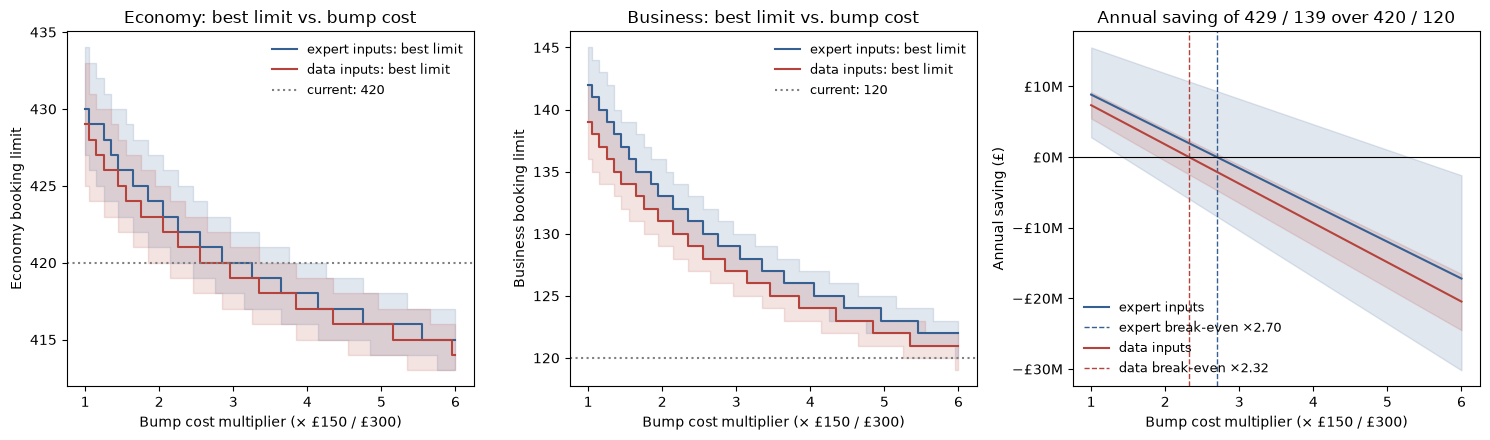

In [36]:
fine_multipliers = np.round(np.arange(1, 6.01, 0.1), 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
colors = {"expert": "#376092", "data": "#b5433c"}

for ax, cabin in zip(axes[:2], ["economy", "business"]):
    for source in ["expert", "data"]:
        empty, bumped = COMPONENTS[(source, cabin)]
        best, low, high = [], [], []
        for multiplier in fine_multipliers:
            expected = cabin_cost(cabin, empty, bumped, multiplier).mean()
            near = expected[expected <= expected.min() + TOLERANCE]
            best.append(expected.idxmin())
            low.append(near.index.min())
            high.append(near.index.max())
        ax.fill_between(fine_multipliers, low, high, color=colors[source], alpha=0.15, step="mid")
        ax.step(fine_multipliers, best, where="mid", color=colors[source], label=f"{source} inputs: best limit")
    ax.axhline(current_limit[cabin], color="grey", linestyle=":", label=f"current: {current_limit[cabin]}")
    ax.set_title(f"{cabin.capitalize()}: best limit vs. bump cost")
    ax.set_xlabel("Bump cost multiplier (× £150 / £300)")
    ax.set_ylabel(f"{cabin.capitalize()} booking limit")
    ax.legend(frameon=False, fontsize=9)

ax = axes[2]
for source in ["expert", "data"]:
    fare_part, bump_part = saving_components(source, *RECOMMENDED)
    savings = np.array([fare_part - m * bump_part for m in fine_multipliers])  # multipliers × outer draws
    ax.fill_between(fine_multipliers, np.quantile(savings, 0.05, axis=1), np.quantile(savings, 0.95, axis=1),
                    color=colors[source], alpha=0.15)
    ax.plot(fine_multipliers, savings.mean(axis=1), color=colors[source], label=f"{source} inputs")
    crossing = fare_part.mean() / bump_part.mean()
    ax.axvline(crossing, color=colors[source], linestyle="--", linewidth=1,
               label=f"{source} break-even ×{crossing:.2f}")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title(f"Annual saving of {RECOMMENDED[0]} / {RECOMMENDED[1]} over 420 / 120")
ax.set_xlabel("Bump cost multiplier (× £150 / £300)")
ax.set_ylabel("Annual saving (£)")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(
    lambda x, _: f"{'−' if x < 0 else ''}£{abs(x) / 1e6:,.0f}M"))
ax.legend(frameon=False, fontsize=9)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "step7a-bump-cost.png", dpi=200, bbox_inches="tight")
plt.close(fig)
fig

**What 7a shows**
- **The best limits fall steadily as bumping gets dearer.** On data inputs they go from 429 / 139 (×1) to 425 / 134 (×1.5), 423 / 131 (×2), 419 / 127 (×3), 417 / 124 (×4) and 414 / 121 (×6). Expert inputs run one to three seats higher at every multiplier. **Economy drops below today's 420 from about ×3. Business stays above 120 even at ×6**, because an empty business seat (£1,450) still costs about as much as a business bump at ×6 (£1,800).
- **The recommendation stops beating 420 / 120 at about ×2.3 on data inputs**, i.e. bump costs of about **£350 economy / £700 business** (90% band ×1.9–×2.8). On expert inputs the break-even is ×2.7, with a much wider band (×1.4–×5.3). At ×2 the recommendation still saves £1.8M a year (P = 89%). At ×3 it *loses* £3.8M a year against today's policy.
- **Re-optimising always beats 420 / 120.** Even at ×6 the right limits for that bump cost save about £1.0M a year. The risk is not in overbooking more as such. It is in **locking in 429 / 139 while the bump cost moves.**
- **So the limits should be tied to the bump cost.** If the competitor's policy pushes our real goodwill cost above about twice today's estimate, the limits need to come down along the curve above. Estimating that goodwill cost properly is worth more than any further refinement of the no-show model.

### 7b. Correlation between the cabins

The Step 6 best policies are rerun under the **common-shock** (latent correlation +0.4) and **divergent** (−0.4, Thanksgiving-type) settings from Step 5, on the same simulated flights. The 420 / 120 rows reuse Step 5's results. Without upgrades the cabins are costed separately, so correlation cannot change the expected cost; what it can change is the **tail** and how often bumping happens. The last three columns are the change from the independent case for the same policy and inputs.

In [37]:
correlation_rows = []
for source in ["expert", "data"]:
    economy_limit, business_limit = best_limits[source]
    for policy_name in ["current 420 / 120", f"best {economy_limit} / {business_limit}"]:
        for setting in CORRELATION_SETTINGS:  # independent first, so it is the reference row below
            if policy_name.startswith("current"):
                simulated = current_policy[(source, setting)]  # already simulated in Step 5
            else:
                simulated = simulate_policy(economy_limit, business_limit, FLIGHT_RATES[(source, setting)])
            row = summarise(simulated)
            row.update({"inputs": source, "policy": policy_name, "correlation": setting})
            correlation_rows.append(row)

correlation_stress = pd.DataFrame(correlation_rows).set_index(["inputs", "policy", "correlation"])
correlation_stress = correlation_stress[["mean cost", "SD", "P95", "CVaR95", "P(any bump)", "P(business bump)"]]
for column in ["P95", "CVaR95", "P(any bump)"]:
    independent = correlation_stress.groupby(level=["inputs", "policy"], sort=False)[column].transform("first")
    correlation_stress[f"{column} vs independent"] = correlation_stress[column] - independent

money_columns = ["mean cost", "SD", "P95", "CVaR95", "P95 vs independent", "CVaR95 vs independent"]
correlation_stress.style.format("£{:,.0f}", subset=money_columns) \
    .format("{:.1%}", subset=["P(any bump)", "P(business bump)"]) \
    .format("{:+.1%}", subset=["P(any bump) vs independent"])

**What 7b shows**
- **The mean doesn't move** (within £10 per flight), as expected without upgrades.
- **A common shock fattens the tail, but much less for the recommendation than for today's policy.** P95 rises by about £450 at 429 / 139 against £2,100 at 420 / 120, and CVaR95 by about £1,450 against £3,100. At 420 / 120 the tail flights are the ones with many empty business seats, and a common shock lines them up with empty economy seats on the same days. The higher limits fill those seats, so there is less tail to line up.
- **Divergent days barely change the recommendation's tail** (P95 +£200, CVaR95 −£200) and make it slightly *more* likely to bump someone (+3 points), because a low-economy, high-business day still bumps in economy.
- **In every setting the recommendation's tail is far below today's:** P95 £24.0–24.4k against £40.1–43.7k, and CVaR95 £34–36k against £49–54k (data inputs).
- **Bumping frequency is the cost:** P(any bump) is 90–97% and P(business bump) 78%, against 60–73% and 34–37% today, in every correlation setting. Correlation does not change that trade-off.

### 7c. Upgrades: bumped economy passengers in spare business seats

**Rule modelled:** on each flight, upgrades = min(economy passengers bumped, empty business seats). Each upgrade avoids the £150 economy bump cost. The business seat still earns no business fare, so its £1,450 empty-seat cost stays in. Business passengers are not moved down into economy.

**The grid now has to be joint.** The upgrade saving depends on both cabins on the same flight, so the Step 6 shortcut (economy cost + business cost) no longer holds. Each cabin is still swept once. Every flight's economy bumps and business empty seats are kept at every limit, and the expected number of upgrades is computed for **all 3,721 pairs** of limits, per outer draw, on the same flights. This is exact, not an approximation. It is repeated for both input sources and all three correlation settings.

Annual value of upgrades, three ways:
- **at 420 / 120:** upgrades added to today's policy;
- **same limits:** upgrades added to the best no-upgrade limits;
- **re-optimised:** best cost without upgrades minus best cost with upgrades after jointly re-optimising, with a 90% band across outer draws.

In [38]:
def upgrade_grid(rates, params=None):
    # Upgrades on a flight = min(economy bumped, business empty), averaged per outer draw for every pair of limits.
    # The economy sweep stores every flight's bumps at every limit; the business sweep then counts upgrades as it goes
    if params is None:
        params = model.base_values()
    flights_per_draw = DAYS_PER_OUTER * FLIGHTS_PER_DAY
    economy_over = []
    upgrades = np.empty((len(ECONOMY_LIMITS), len(BUSINESS_LIMITS), N_OUTER), dtype=np.float32)

    def store_economy_bumps(limit, flight_empty, flight_bumped):
        # 1-byte integers to save memory: at most 60 economy bumps on this grid
        economy_over.append(flight_bumped.astype(np.uint8))

    def count_upgrades(limit, flight_empty, flight_bumped):
        spare = flight_empty.astype(np.uint8)  # at most 100 empty business seats
        j = BUSINESS_LIMITS.index(limit)
        for i, over in enumerate(economy_over):
            upgrades[i, j] = np.minimum(over, spare).sum(axis=(1, 2), dtype=np.int32) / flights_per_draw

    economy = cabin_sweep("economy", rates["economy"], ECONOMY_LIMITS, store_economy_bumps, params)
    business = cabin_sweep("business", rates["business"], BUSINESS_LIMITS, count_upgrades, params)
    return {"economy": economy, "business": business, "upgrades": upgrades}


UPGRADES = {}
for source in ["expert", "data"]:
    for setting in CORRELATION_SETTINGS:
        UPGRADES[(source, setting)] = upgrade_grid(FLIGHT_RATES[(source, setting)])

In [39]:
def joint_costs(result, multiplier=1, upgrades_on=True, params=None):
    # Expected cost per outer draw for every pair of limits: array (economy limits × business limits × draws)
    if params is None:
        params = model.base_values()
    economy = cabin_cost("economy", *result["economy"], multiplier, params).to_numpy().T
    business = cabin_cost("business", *result["business"], multiplier, params).to_numpy().T
    cost = economy[:, None, :] + business[None, :, :]
    if upgrades_on:
        cost = cost - multiplier * params["economy_bump_cost"] * result["upgrades"]
    return cost


def limit_index(economy_limit, business_limit):
    return ECONOMY_LIMITS.index(economy_limit), BUSINESS_LIMITS.index(business_limit)


best_with_upgrades = {}
upgrade_rows = []
for (source, setting), result in UPGRADES.items():
    without = joint_costs(result, upgrades_on=False)
    with_upgrades = joint_costs(result, upgrades_on=True)
    i0, j0 = np.unravel_index(without.mean(axis=2).argmin(), without.shape[:2])
    i1, j1 = np.unravel_index(with_upgrades.mean(axis=2).argmin(), with_upgrades.shape[:2])
    best_with_upgrades[(source, setting)] = (ECONOMY_LIMITS[i1], BUSINESS_LIMITS[j1])
    ic, jc = limit_index(420, 120)
    economy_bump_cost = model.base_values()["economy_bump_cost"]
    value_current = economy_bump_cost * result["upgrades"][ic, jc] * FLIGHTS_PER_YEAR
    value_same_limits = economy_bump_cost * result["upgrades"][i0, j0] * FLIGHTS_PER_YEAR
    value_reoptimised = (without[i0, j0] - with_upgrades[i1, j1]) * FLIGHTS_PER_YEAR
    upgrade_rows.append({
        "inputs": source,
        "correlation": setting,
        "best without upgrades": f"{ECONOMY_LIMITS[i0]} / {BUSINESS_LIMITS[j0]}",
        "cost without upgrades": without[i0, j0].mean(),
        "best with upgrades": f"{ECONOMY_LIMITS[i1]} / {BUSINESS_LIMITS[j1]}",
        "cost with upgrades": with_upgrades[i1, j1].mean(),
        "upgrades per flight": result["upgrades"][i1, j1].mean(),
        "economy bumps left": result["economy"][1][ECONOMY_LIMITS[i1]].mean() - result["upgrades"][i1, j1].mean(),
        "annual value at 420 / 120": value_current.mean(),
        "annual value, same limits": value_same_limits.mean(),
        "annual value, re-optimised": value_reoptimised.mean(),
        "re-optimised 90% low": np.quantile(value_reoptimised, 0.05),
        "re-optimised 90% high": np.quantile(value_reoptimised, 0.95),
    })
    edge = (i1 in (0, len(ECONOMY_LIMITS) - 1)) or (j1 in (0, len(BUSINESS_LIMITS) - 1))
    if edge:
        print(f"Warning: best limits with upgrades ({source}, {setting}) are on the edge of the grid")

upgrade_value = pd.DataFrame(upgrade_rows).set_index(["inputs", "correlation"])
money_columns = ["cost without upgrades", "cost with upgrades", "annual value at 420 / 120",
                 "annual value, same limits", "annual value, re-optimised", "re-optimised 90% low",
                 "re-optimised 90% high"]
upgrade_value.style.format("£{:,.0f}", subset=money_columns) \
    .format("{:.2f}", subset=["upgrades per flight", "economy bumps left"])

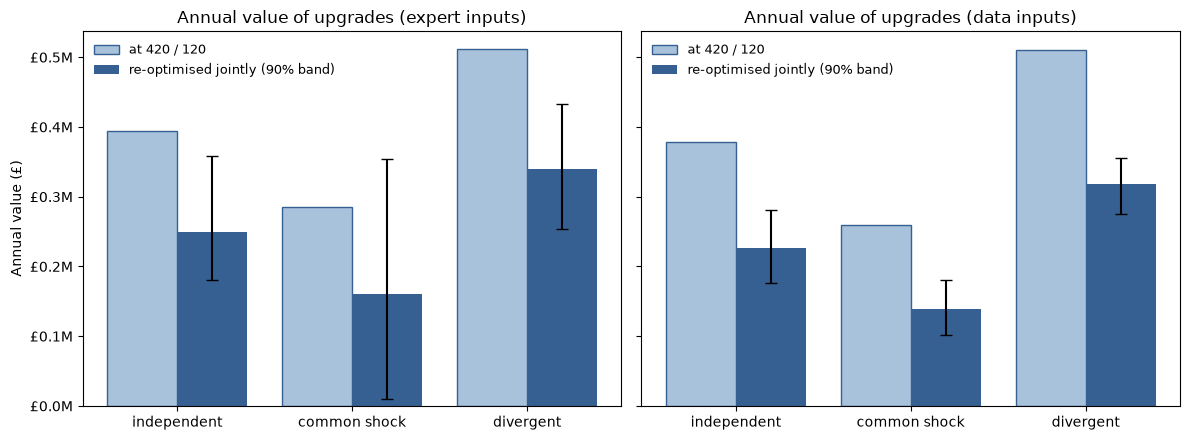

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
settings = list(CORRELATION_SETTINGS)
x = np.arange(len(settings))
for ax, source in zip(axes, ["expert", "data"]):
    rows = upgrade_value.loc[source].reindex(settings)
    ax.bar(x - 0.2, rows["annual value at 420 / 120"], width=0.4, color="#a9c2dc", edgecolor="#376092",
           label="at 420 / 120")
    errors = [rows["annual value, re-optimised"] - rows["re-optimised 90% low"],
              rows["re-optimised 90% high"] - rows["annual value, re-optimised"]]
    ax.bar(x + 0.2, rows["annual value, re-optimised"], width=0.4, color="#376092", yerr=errors, capsize=4,
           label="re-optimised jointly (90% band)")
    ax.set_xticks(x, settings)
    ax.set_title(f"Annual value of upgrades ({source} inputs)")
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, _: f"£{v / 1e6:,.1f}M"))
    ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("Annual value (£)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "step7c-upgrade-value.png", dpi=200, bbox_inches="tight")
plt.close(fig)
fig

**What 7c shows**
- **Upgrades don't change the limits.** The joint optimum is 429 / 139 (independent and common shock) or 429 / 138 (divergent) on data inputs, and 431 / 141–142 on expert inputs. Re-optimising adds almost nothing over simply adding upgrades to the Step 6 limits.
- **They are worth about £0.23M a year on data inputs** (90% band £0.18–0.28M) with independent cabins: about 1 upgrade per flight, out of about 9.5 economy bumps. That is under 2% of the remaining cost.
- **Correlation now matters, as Step 5 anticipated.** A common shock cuts the value to **£0.14M**, because economy is overfull on the same days that business is full, so there are fewer spare seats when they are needed. Divergent days raise it to **£0.32M**, since economy is full exactly when business has seats to spare. Expert inputs give similar figures (£0.16–0.34M) with wider bands.
- **Upgrades are worth more under today's policy** (£0.26–0.51M), because 420 / 120 leaves more business seats empty. As the recommendation fills those seats, the upgrade option shrinks.
- **The verdict:** formalise the practice, since it is free money and staff already do it. But it is a bonus on top of the new limits, not a reason to choose different ones. Two cautions: the log can't tell us how often it already happens (so part of this value may already be in the actual costs), and a known upgrade route could change economy passengers' behaviour.

### 7d. Regret table

**Policies** (all limits fixed in advance):
1. current 420 / 120;
2. best on expert inputs (Step 6);
3. best on data inputs (Step 6);
4. best with upgrades: the 7c joint optimum on data / independent, **with upgrades used in every world**;
5. weekday / weekend split: the data economy limit with Step 6's business limits of 134 on weekdays and 150 at weekends.

**Worlds:** each one fixes the true mean no-show rates, so the epistemic uncertainty is switched off ("what if we knew the truth?"). The per-flight spread and the common random numbers are the same as before.
- **Expert low / mode / high:** the experts' 3% / 5% / 8% economy and 15% / 20% / 30% business, every day.
- **Data mean:** the ordinary-day means from Step 4, with business split by weekday (18.2%) and weekend (26.1%) and each day type's own spread. This lets the split policy show its value.
- **Bump cost × 3:** the data-mean world at £450 / £900.
- **Common shock:** the data-mean world with correlated cabins (+0.4).
- **Thanksgiving-type divergent:** the mean rates actually logged in Thanksgiving week (24–30 Nov), with divergent cabins (−0.4) and the ordinary-day spread.

**Regret** = a policy's expected cost per flight in a world minus the cheapest of the five policies in that world. Worst-case regret is the largest across the seven worlds. A second table shows the best single limits (no upgrades, no split) with hindsight in each world, on a wider grid (economy 400–480, business 100–220), as a check on how far the five candidates are from what was possible.

In [41]:
thanksgiving = clean[clean["date"].between("2025-11-24", "2025-11-30")]


def kappa(cabin, sample):
    fitted = noshow_distributions.loc[(cabin, sample)]
    return fitted["beta alpha"] + fitted["beta beta"]


data_world = {
    "economy": ordinary["econ_noshow_rate"].mean(),
    "business": {"weekday": (ordinary_weekday["bus_noshow_rate"].mean(), kappa("business", "weekday (Mon–Fri), ordinary")),
                 "weekend": (ordinary_weekend["bus_noshow_rate"].mean(), kappa("business", "weekend (Sat–Sun), ordinary"))},
    "setting": "independent",
    "bump cost ×": 1,
}


def same_every_day(mean):
    return {"weekday": (mean, CONCENTRATION["business"]), "weekend": (mean, CONCENTRATION["business"])}


WORLDS = {}
for label, index in [("low", 0), ("mode", 1), ("high", 2)]:
    WORLDS[f"expert {label}"] = {
        "economy": EXPERT_RANGE["econ_noshow_rate"][index],
        "business": same_every_day(EXPERT_RANGE["bus_noshow_rate"][index]),
        "setting": "independent",
        "bump cost ×": 1,
    }
WORLDS["data mean"] = data_world
WORLDS["bump cost × 3"] = {**data_world, "bump cost ×": 3}
WORLDS["common shock"] = {**data_world, "setting": "common shock"}
WORLDS["Thanksgiving-type divergent"] = {
    "economy": thanksgiving["econ_noshow_rate"].mean(),
    "business": same_every_day(thanksgiving["bus_noshow_rate"].mean()),
    "setting": "divergent",
    "bump cost ×": 1,
}

world_table = pd.DataFrame({
    name: {
        "economy no-show": world["economy"],
        "business no-show, weekdays": world["business"]["weekday"][0],
        "business no-show, weekends": world["business"]["weekend"][0],
        "correlation": world["setting"],
        "bump cost ×": world["bump cost ×"],
    }
    for name, world in WORLDS.items()
}).T
world_table.style.format("{:.1%}", subset=["economy no-show", "business no-show, weekdays",
                                            "business no-show, weekends"])

,economy no-show,"business no-show, weekdays","business no-show, weekends",correlation,bump cost ×
expert low,3.0%,15.0%,15.0%,independent,1
expert mode,5.0%,20.0%,20.0%,independent,1
expert high,8.0%,30.0%,30.0%,independent,1
data mean,5.2%,18.2%,26.1%,independent,1
bump cost × 3,5.2%,18.2%,26.1%,independent,3
common shock,5.2%,18.2%,26.1%,common shock,1
Thanksgiving-type divergent,1.5%,36.5%,36.5%,divergent,1


In [42]:
REGRET_ECONOMY_LIMITS = list(range(400, 481))
REGRET_BUSINESS_LIMITS = list(range(100, 221))
upgrade_policy = best_with_upgrades[("data", "independent")]
REGRET_POLICIES = {
    "current 420 / 120": {"economy": 420, "weekday": 120, "weekend": 120, "upgrades": False},
    f"best on expert {best_limits['expert'][0]} / {best_limits['expert'][1]}":
        {"economy": best_limits["expert"][0], "weekday": best_limits["expert"][1],
         "weekend": best_limits["expert"][1], "upgrades": False},
    f"best on data {best_limits['data'][0]} / {best_limits['data'][1]}":
        {"economy": best_limits["data"][0], "weekday": best_limits["data"][1],
         "weekend": best_limits["data"][1], "upgrades": False},
    f"best with upgrades {upgrade_policy[0]} / {upgrade_policy[1]}":
        {"economy": upgrade_policy[0], "weekday": upgrade_policy[1], "weekend": upgrade_policy[1], "upgrades": True},
    f"split {best_limits['data'][0]} / {weekday_best} weekdays, {weekend_best} weekends":
        {"economy": best_limits["data"][0], "weekday": weekday_best, "weekend": weekend_best, "upgrades": False},
}


def correlated_noise(setting):
    # Same day factor and per-flight noise as Step 5, combined for one correlation setting
    rho = CORRELATION_SETTINGS[setting]["rho"]
    sign = CORRELATION_SETTINGS[setting]["economy_sign"]
    economy_z = sign * np.sqrt(rho) * CRN["day_factor"] + np.sqrt(1 - rho) * CRN["economy_noise"]
    business_z = np.sqrt(rho) * CRN["day_factor"] + np.sqrt(1 - rho) * CRN["business_noise"]
    return economy_z, business_z


def fixed_mean_rate(z, mean, concentration):
    # Per-flight rates from a beta with a known mean: the epistemic uncertainty is switched off in a world
    return stats.beta.ppf(stats.norm.cdf(z), mean * concentration, (1 - mean) * concentration)


def evaluate_world(world):
    economy_z, business_z = correlated_noise(world["setting"])
    economy_rate = fixed_mean_rate(economy_z, world["economy"], CONCENTRATION["economy"])
    economy_empty, economy_bumped = cabin_sweep("economy", economy_rate, REGRET_ECONOMY_LIMITS)
    economy_curve = cabin_cost("economy", economy_empty, economy_bumped, world["bump cost ×"]).mean()

    business_curves = {}
    upgrades = {}
    for day_type, (mean, concentration) in world["business"].items():
        if day_type == "weekend" and world["business"]["weekend"] == world["business"]["weekday"]:
            business_curves["weekend"] = business_curves["weekday"]  # no weekday/weekend difference in this world
            upgrades["weekend"] = upgrades["weekday"]
            continue
        business_rate = fixed_mean_rate(business_z, mean, concentration)
        business_empty, business_bumped = cabin_sweep("business", business_rate, REGRET_BUSINESS_LIMITS)
        business_curves[day_type] = cabin_cost("business", business_empty, business_bumped,
                                               world["bump cost ×"]).mean()
        over = np.maximum(cabin_shows("economy", upgrade_policy[0], economy_rate, 400) - 400, 0)
        spare = np.maximum(100 - cabin_shows("business", upgrade_policy[1], business_rate, 100), 0)
        upgrades[day_type] = np.minimum(over, spare).mean()

    costs = {}
    for name, policy in REGRET_POLICIES.items():
        cost = economy_curve[policy["economy"]]
        for day_type in ["weekday", "weekend"]:
            weight = DAY_TYPES[day_type]["weight"]
            cost += weight * business_curves[day_type][policy[day_type]]
            if policy["upgrades"]:
                cost -= weight * world["bump cost ×"] * model.base_values()["economy_bump_cost"] * upgrades[day_type]
        costs[name] = cost

    single_business = sum(DAY_TYPES[d]["weight"] * business_curves[d] for d in ["weekday", "weekend"])
    if single_business.idxmin() == REGRET_BUSINESS_LIMITS[-1] or economy_curve.idxmin() == REGRET_ECONOMY_LIMITS[-1]:
        print("Warning: the hindsight-best limits are on the edge of the grid")
    hindsight = {
        "economy": economy_curve.idxmin(),
        "business": single_business.idxmin(),
        "cost": economy_curve.min() + single_business.min(),
    }
    return costs, hindsight


world_costs = {}
world_hindsight = {}
for name, world in WORLDS.items():
    world_costs[name], world_hindsight[name] = evaluate_world(world)

In [43]:
cost_table = pd.DataFrame(world_costs)
regret = cost_table - cost_table.min()
regret["worst-case regret"] = regret.max(axis=1)
regret["worst-case regret, annual"] = regret["worst-case regret"] * FLIGHTS_PER_YEAR
regret = regret.sort_values("worst-case regret")

world_columns = list(WORLDS)
regret.style.format("£{:,.0f}") \
    .background_gradient(cmap="Reds", subset=world_columns, axis=None) \
    .highlight_min(subset=["worst-case regret"], color="#c6e2c3")

,expert low,expert mode,expert high,data mean,bump cost × 3,common shock,Thanksgiving-type divergent,worst-case regret,"worst-case regret, annual"
best with upgrades 429 / 139,£832,£0,"£1,013",£347,"£2,101",£401,£0,"£2,101","£3,068,040"
"split 429 / 134 weekdays, 150 weekends","£1,035",£512,"£1,963",£0,"£1,592",£0,"£2,456","£2,456","£3,586,284"
best on data 429 / 139,£908,£146,"£1,219",£500,"£2,561",£500,"£1,722","£2,561","£3,739,630"
best on expert 430 / 142,"£1,532",£281,£0,£564,"£4,049",£564,£169,"£4,049","£5,911,470"
current 420 / 120,£0,"£4,581","£15,205","£5,557",£0,"£5,561","£14,742","£15,205","£22,199,944"


In [44]:
hindsight_table = pd.DataFrame(world_hindsight).T
hindsight_table["best candidate"] = cost_table.idxmin()
hindsight_table["best candidate cost"] = cost_table.min()
hindsight_table["gap to hindsight"] = hindsight_table["best candidate cost"] - hindsight_table["cost"]
hindsight_table = hindsight_table.rename(columns={"economy": "hindsight economy", "business": "hindsight business",
                                                  "cost": "hindsight cost"})
hindsight_table.index.name = "world"
hindsight_table.style.format("{:.0f}", subset=["hindsight economy", "hindsight business"]) \
    .format(lambda x: f"{'−' if x < 0 else ''}£{abs(x):,.0f}",
            subset=["hindsight cost", "best candidate cost", "gap to hindsight"])

,hindsight economy,hindsight business,hindsight cost,best candidate,best candidate cost,gap to hindsight
world,,,,,,
expert low,417,128,"£7,467",current 420 / 120,"£8,378",£911
expert mode,428,138,"£9,038",best with upgrades 429 / 139,"£8,909",−£129
expert high,444,162,"£11,667",best on expert 430 / 142,"£15,563","£3,896"
data mean,429,139,"£9,145","split 429 / 134 weekdays, 150 weekends","£8,645",−£500
bump cost × 3,419,127,"£15,738",current 420 / 120,"£16,911","£1,173"
common shock,429,139,"£9,144","split 429 / 134 weekdays, 150 weekends","£8,645",−£500
Thanksgiving-type divergent,409,182,"£11,130",best with upgrades 429 / 139,"£22,254","£11,124"


**What 7d shows**
- **Today's policy is only right if bumping is much dearer or no-shows sit at the experts' low end.** It has zero regret in the *expert low* and *bump cost × 3* worlds, and £4.6k–£15.2k per flight in every other world. Its worst case is **£15.2k per flight (£22.2M a year)** if no-shows are at the experts' high end.
- **All four new policies cut the worst-case regret by a factor of 4–7.** The minimax-regret choice is **429 / 139 with upgrades**: its worst case is £2.1k per flight (£3.1M a year), in the *bump cost × 3* world. Without upgrades the same limits have a worst case of £2.6k (£3.7M a year). The expert-based 430 / 142 is clearly worse (£4.0k), because it overbooks more and so suffers more when bumping gets dearer.
- **Bump cost × 3 is the world that hurts every new policy most.** This matches 7a: ×3 is past the ×2.3 break-even. The bump cost is the one input that could make the change a mistake.
- **The split policy wins whenever weekdays and weekends really differ** (data-mean and common-shock worlds): about £500 per flight better than 429 / 139 alone, and £350 better than 429 / 139 with upgrades. But its weekend limit of 150 is costly when there is no weekend effect, or in a Thanksgiving-type week (worst case £2.5k). Combining the split with upgrades is the natural next candidate.
- **A Thanksgiving-type week defeats every fixed policy.** With hindsight the right limits that week are about **409 / 182**, at £11.1k per flight, against £22.3k for the best candidate. Holiday and disruption weeks need their own override, set from bookings data for those dates, rather than a better year-round number.
- **Negative gaps in the hindsight table** are not errors. The hindsight limits are a single pair with no upgrades and no split, so policies 4 and 5 can beat them.

### 7e. Sensitivity: which input matters most?

One input at a time is moved to the ends of a plausible range, with everything else at the base case: the ordinary-day data means (economy 5.2%, business 20.6% every day), independent cabins, and £150 / £300 bump costs. For each end the table shows:
- the expected cost per flight of the **fixed** recommendation 429 / 139;
- the **best limits** for that input value;
- the **regret** of staying at 429 / 139 instead of moving to those limits.

| Input | Low | High | Why this range |
|---|---|---|---|
| Economy / business no-show mean | 3% / 15% | 8% / 30% | The experts' full range |
| Economy / business bump cost | ×0.5 | ×3 | ×3 is the regret-table world, beyond the 7a break-even |
| Economy / business per-flight spread | SD ≈ ×0.5 | SD ≈ ×2 | Beta concentration divided by (SD multiplier)², i.e. half or double the flight-to-flight variation fitted in Step 4 |

Correlation is left out on purpose. Without upgrades it has no effect on the expected cost (7b), and with upgrades it moves the cost by only about ±£0.1M a year (7c).

In [45]:
TORNADO_BASE = {
    "economy mean": ordinary["econ_noshow_rate"].mean(),
    "business mean": ordinary["bus_noshow_rate"].mean(),
    "economy spread ×": 1,
    "business spread ×": 1,
    "economy bump ×": 1,
    "business bump ×": 1,
}
TORNADO_SWINGS = [
    ("economy no-show mean", "economy mean", 0.03, 0.08, "{:.0%}"),
    ("business no-show mean", "business mean", 0.15, 0.30, "{:.0%}"),
    ("economy bump cost", "economy bump ×", 0.5, 3, "£{:,.0f}"),
    ("business bump cost", "business bump ×", 0.5, 3, "£{:,.0f}"),
    ("economy per-flight spread", "economy spread ×", 0.5, 2, "SD ≈ ×{:.1f}"),
    ("business per-flight spread", "business spread ×", 0.5, 2, "SD ≈ ×{:.1f}"),
]


def tornado_cabin_curve(cabin, inputs):
    # Expected cost of one cabin for each limit, with known mean (independent cabins, single limit every day)
    limits = REGRET_ECONOMY_LIMITS if cabin == "economy" else REGRET_BUSINESS_LIMITS
    mean = inputs[f"{cabin} mean"]
    # Spread × s scales the per-flight SD by about s, i.e. the concentration by 1 / s²
    concentration = CONCENTRATION[cabin] / inputs[f"{cabin} spread ×"] ** 2
    rate = fixed_mean_rate(CRN[f"{cabin}_noise"], mean, concentration)
    empty, bumped = cabin_sweep(cabin, rate, limits)
    return empty.mean(), bumped.mean()


tornado_components = {cabin: tornado_cabin_curve(cabin, TORNADO_BASE) for cabin in ["economy", "business"]}


def tornado_outcome(inputs, components):
    outcome = {}
    total_fixed = 0
    total_best = 0
    for cabin, limit in [("economy", RECOMMENDED[0]), ("business", RECOMMENDED[1])]:
        curve = cabin_cost(cabin, *components[cabin], inputs[f"{cabin} bump ×"])
        total_fixed += curve[limit]
        total_best += curve.min()
        outcome[f"best {cabin}"] = curve.idxmin()
    outcome["cost at recommended"] = total_fixed
    outcome["cost re-optimised"] = total_best
    return outcome


tornado_base = tornado_outcome(TORNADO_BASE, tornado_components)
tornado_rows = []
for label, key, low, high, value_format in TORNADO_SWINGS:
    cabin = key.split()[0]
    row = {"input": label}
    for end, value in [("low", low), ("high", high)]:
        inputs = {**TORNADO_BASE, key: value}
        components = dict(tornado_components)
        if "bump" not in key:
            components[cabin] = tornado_cabin_curve(cabin, inputs)
        outcome = tornado_outcome(inputs, components)
        shown = value * model.base_values()[f"{cabin}_bump_cost"] if "bump" in key else value
        row[f"{end} value"] = value_format.format(shown)
        row[f"cost at {end}"] = outcome["cost at recommended"]
        row[f"best limits at {end}"] = f"{outcome['best economy']} / {outcome['best business']}"
        row[f"best economy at {end}"] = outcome["best economy"]
        row[f"best business at {end}"] = outcome["best business"]
        row[f"regret at {end}"] = outcome["cost at recommended"] - outcome["cost re-optimised"]
    row["cost swing"] = abs(row["cost at high"] - row["cost at low"])
    tornado_rows.append(row)

tornado = pd.DataFrame(tornado_rows).set_index("input").sort_values("cost swing", ascending=False)
print(f"Base case (data means, base spread and bump costs): cost at {RECOMMENDED[0]} / {RECOMMENDED[1]} "
      f"£{tornado_base['cost at recommended']:,.0f} per flight; best limits "
      f"{tornado_base['best economy']} / {tornado_base['best business']}")
tornado[["low value", "high value", "cost at low", "cost at high", "cost swing", "best limits at low",
         "best limits at high", "regret at low", "regret at high"]].style.format(
    "£{:,.0f}", subset=["cost at low", "cost at high", "cost swing", "regret at low", "regret at high"])

Base case (data means, base spread and bump costs): cost at 429 / 139 £9,190 per flight; best limits 429 / 139


,low value,high value,cost at low,cost at high,cost swing,best limits at low,best limits at high,regret at low,regret at high
input,,,,,,,,,
business per-flight spread,SD ≈ ×0.5,SD ≈ ×2.0,"£6,493","£16,216","£9,723",429 / 134,429 / 144,£282,£107
business bump cost,£150,£900,"£7,327","£16,638","£9,310",429 / 148,429 / 127,£407,"£2,611"
business no-show mean,15%,30%,"£9,123","£14,869","£5,746",429 / 128,429 / 162,"£1,035","£3,854"
economy bump cost,£75,£450,"£8,482","£12,019","£3,537",435 / 139,419 / 139,£144,"£1,155"
economy per-flight spread,SD ≈ ×0.5,SD ≈ ×2.0,"£8,150","£11,522","£3,371",426 / 139,430 / 139,£59,£1
economy no-show mean,3%,8%,"£9,352","£11,102","£1,750",417 / 139,444 / 139,£784,"£1,262"


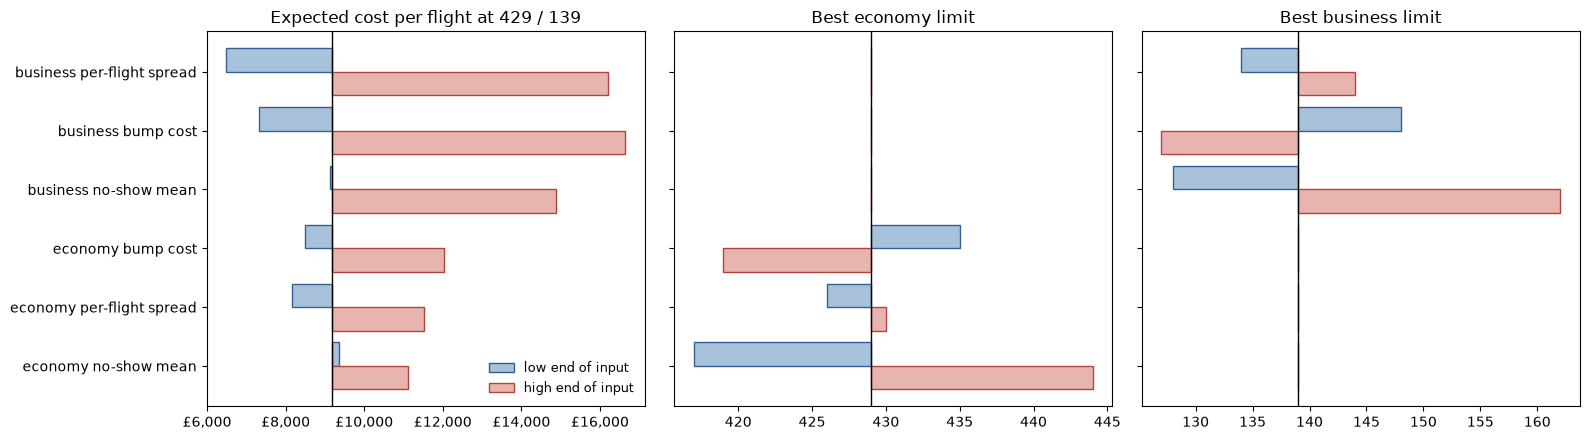

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
ordered = tornado.sort_values("cost swing")
panels = [
    ("cost at", tornado_base["cost at recommended"],
     f"Expected cost per flight at {RECOMMENDED[0]} / {RECOMMENDED[1]}", "£{x:,.0f}"),
    ("best economy at", tornado_base["best economy"], "Best economy limit", "{x:.0f}"),
    ("best business at", tornado_base["best business"], "Best business limit", "{x:.0f}"),
]
rows = np.arange(len(ordered))
for ax, (prefix, base, title, tick_format) in zip(axes, panels):
    low = ordered[f"{prefix} low"].astype(float)
    high = ordered[f"{prefix} high"].astype(float)
    # Low and high ends side by side, so neither hides the other when both move the same way
    ax.barh(rows + 0.2, low - base, left=base, height=0.4, color="#a9c2dc", edgecolor="#376092",
            label="low end of input")
    ax.barh(rows - 0.2, high - base, left=base, height=0.4, color="#e8b4b0", edgecolor="#b5433c",
            label="high end of input")
    ax.axvline(base, color="black", linewidth=1)
    ax.set_yticks(rows, ordered.index)
    ax.set_title(title)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter(tick_format))
axes[0].legend(frameon=False, fontsize=9, loc="lower right")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "step7e-tornado.png", dpi=200, bbox_inches="tight")
plt.close(fig)
fig

**What 7e shows**
- **Business inputs dominate the cost.** The business per-flight spread (£6.5k–£16.2k per flight), the business bump cost (£7.3k–£16.6k) and the business no-show mean (£9.1k–£14.9k) are the three widest bars. All three economy inputs swing the cost by less than £3.6k.
- **What moves the cost is not always what moves the decision.** The per-flight spread is the top cost driver but shifts the best limits only a little (business 134–144, economy 426–430), so getting it wrong changes the budget, not the policy: regret is under £300 per flight.
- **The decision is driven by the means and the bump costs.** The best business limit runs from 128 to 162 across the business no-show range and from 148 to 127 across the business bump-cost range. The best economy limit runs from 417 to 444 across the economy no-show range and from 435 to 419 across the economy bump-cost range. Each input moves only its own cabin's limit, because without upgrades the cabins are costed separately.
- **The biggest regrets come from a business no-show mean at 30%** (£3.9k per flight: the limit should be 162) and **a business bump cost at ×3** (£2.6k: the limit should be 127). These are the two numbers most worth pinning down. The first is already well measured: the day-level CI from Step 4 is about ±1.5–2 points, not 15–30%. The second, the business goodwill cost, has never been measured at all.

### What Step 7 shows
- **The recommendation is robust to everything except the bump cost.** It holds across expert vs. data inputs, all three correlation settings and the upgrade question. It stops beating 420 / 120 if bump costs rise to about **2.3× today's estimate (about £350 / £700)**, and the competitor's policy is exactly what could cause that.
- **On minimax regret, 429 / 139 with upgrades formalised is the best of the five candidates.** Its worst case is £2.1k per flight, against £15.2k for today's policy. Upgrades themselves are a small bonus (about £0.14–0.32M a year, depending on correlation) and don't change the limits.
- **Correlation matters for risk, not the average.** The recommendation's tail is less exposed to common shocks than today's policy, and stays far below it in every setting.
- **Two things a single number can't handle:** (1) a bump-cost rule, i.e. the limits table from 7a as a lookup to update once the goodwill cost is re-estimated, and (2) a holiday/disruption override, since no fixed policy comes close in a Thanksgiving-type week.
- **The data most worth collecting:** the true goodwill cost of a bump, especially in business, ahead of any further refinement of the no-show model.

## Step 8: The no-refund question

Finance wants to stop refunding no-shows. This step switches from cost to **profit per flight**:

- **With refunds (today):** fare × passengers flown − bump cost × passengers bumped. This is the full-plane revenue minus the Step 1 cost, so the two objectives agree.
- **Without refunds:** the same, **plus the fares that no-shows keep paying**: fare × bookings × no-show rate.

Dropping refunds can change behaviour in two ways, and neither can be measured from the log. So both are set on a grid:

| Input | Values | How it enters |
|---|---|---|
| **No-show rate** | 100% / 75% / 50% / 25% of today's | Scales the mean no-show rate in both cabins (ordinary-day means from Step 4: 5.2% / 20.6%). The per-flight spread (beta concentration) is kept. |
| **Demand loss** | 0 / 5 / 10 / 20% | Fewer people book: bookings = min(limit, demand), with demand cut by the same share in both cabins. |

In each cell the booking limits are **re-optimised** for that cell.

**Assumptions to keep in view:**
- **"Today" is refunds with the limits re-optimised in the same model (429 / 139), not 420 / 120 literally.** Comparing with 420 / 120 would mix the refund decision with the re-optimisation gain from Step 6. The first cell prints the amount to add to every cell for a comparison with 420 / 120.
- **Today's demand is set exactly at the refund-optimal limits (`DEMAND_HEADROOM = 0`).** The log can't show true demand, because bookings hit the limit on every flight. So any demand loss costs bookings straight away. This is the cautious case. If demand really runs well above the limits, a small loss costs nothing.
- **Exact expectations.** With the mean no-show rate fixed in each cell (as in 7d and 7e), show-ups are beta-binomial, so the expected profit is computed exactly rather than simulated. The first cell checks the result against the 7e simulation.

In [47]:
NOSHOW_SCALES = [1.0, 0.75, 0.5, 0.25]  # no-show mean as a share of today's
DEMAND_LOSSES = [0.0, 0.05, 0.10, 0.20]
DEMAND_HEADROOM = 0.0  # demand today above the refund-optimal limits; 0 is the cautious case
NOSHOW_TODAY = {"economy": ordinary["econ_noshow_rate"].mean(), "business": ordinary["bus_noshow_rate"].mean()}
PROFIT_LIMITS = {"economy": REGRET_ECONOMY_LIMITS, "business": REGRET_BUSINESS_LIMITS}


def cabin_profit_by_bookings(cabin, noshow_scale, refund, params=None):
    # Expected profit of one cabin for every number of bookings n, with the mean no-show rate known.
    # Show-ups are beta-binomial, so the expectation is exact; no simulation needed
    if params is None:
        params = model.base_values()
    capacity = params[f"{cabin}_capacity"]
    fare = params[f"{cabin}_fare"]
    bump_cost = params[f"{cabin}_bump_cost"]
    mean = noshow_scale * NOSHOW_TODAY[cabin]
    kappa = CONCENTRATION[cabin]

    profit = {}
    for n in range(1, PROFIT_LIMITS[cabin][-1] + 1):
        shows = np.arange(n + 1)
        pmf = stats.betabinom.pmf(shows, n, (1 - mean) * kappa, mean * kappa)
        flown = (pmf * np.minimum(shows, capacity)).sum()
        bumped = (pmf * np.maximum(shows - capacity, 0)).sum()
        profit[n] = fare * flown - bump_cost * bumped
        if not refund:
            profit[n] += fare * n * mean  # no-shows keep their fare
    return pd.Series(profit)


def best_limit(cabin, profit, demand):
    # Bookings = min(limit, demand): any limit above demand books the same flights
    limits = np.array(PROFIT_LIMITS[cabin])
    bookings = np.minimum(limits, int(min(demand, limits[-1])))
    value = profit[bookings].to_numpy()
    best = value.argmax()
    if limits[best] == limits[-1] and demand > limits[-1]:
        print(f"Warning: best {cabin} limit is on the edge of the grid")
    return bookings[best], value[best]


# Today: refunds kept, limits re-optimised in this same model
PROFIT_TODAY = {cabin: cabin_profit_by_bookings(cabin, 1.0, refund=True) for cabin in PROFIT_LIMITS}
DEMAND_TODAY = {}
profit_today = 0
for cabin in PROFIT_LIMITS:
    limit, value = best_limit(cabin, PROFIT_TODAY[cabin], np.inf)
    DEMAND_TODAY[cabin] = int(limit * (1 + DEMAND_HEADROOM))
    profit_today += value

params = model.base_values()
full_plane = (params["economy_fare"] * params["economy_capacity"]
              + params["business_fare"] * params["business_capacity"])
print(f"Today (refunds, best limits {DEMAND_TODAY['economy']} / {DEMAND_TODAY['business']}): "
      f"profit £{profit_today:,.0f} per flight, i.e. cost £{full_plane - profit_today:,.0f}")
print(f"Check against the 7e simulation at {RECOMMENDED[0]} / {RECOMMENDED[1]}: "
      f"cost £{tornado_base['cost at recommended']:,.0f}, best limits "
      f"{tornado_base['best economy']} / {tornado_base['best business']}")
current_profit = PROFIT_TODAY["economy"][420] + PROFIT_TODAY["business"][120]
print(f"Literal 420 / 120 with refunds: £{(profit_today - current_profit) * FLIGHTS_PER_YEAR / 1e6:,.1f}M a year "
      f"below that, so add this to every cell below to compare against 420 / 120 itself")

Today (refunds, best limits 429 / 139): profit £315,814 per flight, i.e. cost £9,186
Check against the 7e simulation at 429 / 139: cost £9,190, best limits 429 / 139
Literal 420 / 120 with refunds: £7.3M a year below that, so add this to every cell below to compare against 420 / 120 itself


In [48]:
PROFIT_NO_REFUND = {}
for scale in NOSHOW_SCALES:
    for cabin in PROFIT_LIMITS:
        PROFIT_NO_REFUND[(scale, cabin)] = cabin_profit_by_bookings(cabin, scale, refund=False)


def no_refund_cell(scale, loss):
    result = {"profit": 0}
    for cabin in PROFIT_LIMITS:
        demand = DEMAND_TODAY[cabin] * (1 - loss)
        limit, value = best_limit(cabin, PROFIT_NO_REFUND[(scale, cabin)], demand)
        result[f"{cabin} bookings"] = limit  # the best limit, or demand when demand is below it
        result["profit"] += value
    result["change per flight"] = result["profit"] - profit_today
    result["annual change"] = result["change per flight"] * FLIGHTS_PER_YEAR
    return result


refund_rows = []
for scale in NOSHOW_SCALES:
    for loss in DEMAND_LOSSES:
        row = no_refund_cell(scale, loss)
        row.update({"no-show rate": scale, "demand loss": loss})
        refund_rows.append(row)

no_refund = pd.DataFrame(refund_rows).set_index(["no-show rate", "demand loss"])
no_refund = no_refund[["economy bookings", "business bookings", "profit", "change per flight", "annual change"]]
no_refund.style.format("£{:,.0f}", subset=["profit", "change per flight", "annual change"]) \
    .format_index("{:.0%}", level=[0, 1])

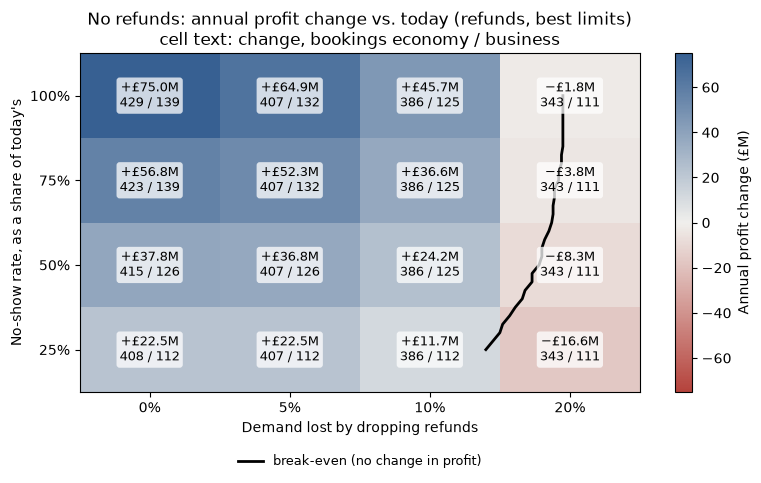

In [49]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

change = no_refund["annual change"].unstack("demand loss").loc[NOSHOW_SCALES, DEMAND_LOSSES] / 1e6

# Break-even: for each no-show rate on a fine grid, the demand loss at which the change crosses zero
fine_scales = np.linspace(0.25, 1.0, 31)
fine_losses = np.linspace(0, 0.30, 301)
fine_profit = {(scale, cabin): cabin_profit_by_bookings(cabin, scale, refund=False)
               for scale in fine_scales for cabin in PROFIT_LIMITS}
breakeven_loss = []
for scale in fine_scales:
    gains = []
    for loss in fine_losses:
        profit = sum(best_limit(cabin, fine_profit[(scale, cabin)], DEMAND_TODAY[cabin] * (1 - loss))[1]
                     for cabin in PROFIT_LIMITS)
        gains.append(profit - profit_today)
    gains = np.array(gains)
    crossing = np.flatnonzero(gains <= 0)
    breakeven_loss.append(fine_losses[crossing[0]] if len(crossing) else np.nan)  # nan: still gains at 30%
breakeven_loss = np.array(breakeven_loss)

# Columns are categories at uneven steps (0, 5, 10, 20%), so the line maps loss to column position piecewise
column_of = lambda loss: np.interp(loss, DEMAND_LOSSES, range(len(DEMAND_LOSSES)))
row_of = lambda scale: np.interp(scale, NOSHOW_SCALES[::-1], range(len(NOSHOW_SCALES))[::-1])

fig, ax = plt.subplots(figsize=(8, 5))
diverging = LinearSegmentedColormap.from_list("loss_gain", ["#b5433c", "#f0efec", "#376092"])
limit = np.abs(change.to_numpy()).max()
image = ax.imshow(change.to_numpy(), cmap=diverging, norm=TwoSlopeNorm(0, -limit, limit), aspect="auto")
for i, scale in enumerate(NOSHOW_SCALES):
    for j, loss in enumerate(DEMAND_LOSSES):
        cell = no_refund.loc[(scale, loss)]
        value = change.iloc[i, j]
        ax.text(j, i, f"{'+' if value >= 0 else '−'}£{abs(value):,.1f}M\n"
                      f"{cell['economy bookings']:.0f} / {cell['business bookings']:.0f}",
                ha="center", va="center", fontsize=9, zorder=3,
                bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "alpha": 0.75, "edgecolor": "none"})

inside = breakeven_loss <= DEMAND_LOSSES[-1]
ax.plot(column_of(breakeven_loss[inside]), row_of(fine_scales[inside]), color="black", linewidth=2,
        label="break-even (no change in profit)")
ax.set_xticks(range(len(DEMAND_LOSSES)), [f"{loss:.0%}" for loss in DEMAND_LOSSES])
ax.set_yticks(range(len(NOSHOW_SCALES)), [f"{scale:.0%}" for scale in NOSHOW_SCALES])
ax.set_xlabel("Demand lost by dropping refunds")
ax.set_ylabel("No-show rate, as a share of today's")
ax.set_title("No refunds: annual profit change vs. today (refunds, best limits)\ncell text: change, bookings economy / business")
fig.colorbar(image, ax=ax, label="Annual profit change (£M)")
ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.15))
fig.tight_layout()
fig.savefig(FIGURE_DIR / "step8-no-refund-heatmap.png", dpi=200, bbox_inches="tight")
plt.close(fig)
fig

**What Step 8 shows**
- **Demand loss decides the answer; the no-show response barely moves it.** Dropping refunds raises profit as long as it loses less than about **14–19.5% of bookings**. The break-even is 19.5% if no-show rates stay the same and falls to about 14% if they drop to a quarter of today's. Every cell up to 10% demand loss is a gain, and every cell at 20% is a loss.
- **The headline gain is large, but only if no one reacts.** With unchanged behaviour, the kept no-show fares are worth about **£75M a year** (£51k per flight), mostly from business: 20.6% of 139 bookings at £1,450. That cell is the least likely: a no-refund ticket changes the product.
- **Reading the cells:** the second line is bookings per flight, economy / business. Where it is below the refund-optimal 429 / 139, demand is the binding constraint and any limit at or above it books the same; a figure below 400 (e.g. 343) means economy flies with empty seats however the limit is set.
- **Fewer no-shows shrink the gain but don't wipe it out.** Less fare is kept, but fewer seats fly empty and the limits come down (to about 408 / 112 at a quarter of today's no-shows), which cuts bumping. At 5% demand loss the gain is still £22–65M a year across the no-show range.
- **Business no-shows are worth more than a business bump costs.** Without refunds and with today's no-show rate, another business booking is worth 20.6% × £1,450 ≈ £299 from a no-show, against 79.4% × £300 ≈ £238 from a bump. So the model would overbook business without limit, and only the demand cap stops it. This means the £300 business bump cost is too low for a heavily overbooked, non-refundable business cabin. A passenger who paid £1,450 non-refundable and then gets bumped will be angrier than today's.
- **The literal 420 / 120 comparison** adds about £7.3M a year to every cell. That is the Step 6 re-optimisation gain, not a refund effect.

**What to check before trusting either answer:**
1. **Demand loss by cabin.** This is the number that decides it, and the log can't show it, because bookings are always at the limit. Business travellers are the ones paying for flexibility, so business may lose far more than 20%.
2. **Real demand headroom.** Rerun with `DEMAND_HEADROOM` above 0 if the booking system shows requests turned away at the limit. Headroom pushes the break-even line to the right.
3. **What the competition does.** If competitors keep refunds, part of the demand loss is our customers switching to them, and it lands on the route's most valuable segment.
4. **A test rather than a switch.** The alternative to an all-or-nothing change is to sell a cheaper non-refundable fare **alongside** the refundable one. That measures demand loss and the no-show response directly, and it is how many full-service carriers already handle it.

## Step 9: Summary for the report

One table comparing the three policies the report discusses, on the base case: **data inputs, independent cabins**, the same simulated flights as Steps 5–7.

- **Current:** 420 / 120.
- **Recommended:** the Step 6 limits (`SUMMARY_LIMITS`, set to `RECOMMENDED`). Change that one line if the report recommends other limits; everything below follows.
- **Recommended + upgrades:** the same limits, with bumped economy passengers moved into empty business seats when there are any (the 7c rule: the business seat still earns no business fare, and the economy bump cost is avoided).

Annual figures are per flight × 4 flights × 365 days. Savings are against 420 / 120, computed per outer draw on the same flights, so the 90% band and P(saving > 0) reflect epistemic uncertainty only. The break-even bump cost is the multiplier on £150 / £300 at which the policy stops beating 420 / 120 (as in 7a). Worst-case regret comes from the 7d table, so it is measured against the cheapest of the five 7d candidates in each world.

The table is saved to `report/policy_summary.csv` as raw numbers, metrics as rows and policies as columns.

In [50]:
SUMMARY_LIMITS = RECOMMENDED  # 429 / 139 from Step 6
SUMMARY_POLICIES = {
    "current": {"limits": (420, 120), "upgrades": False},
    "recommended": {"limits": SUMMARY_LIMITS, "upgrades": False},
    "recommended + upgrades": {"limits": SUMMARY_LIMITS, "upgrades": True},
}
SUMMARY_RATES = FLIGHT_RATES[("data", "independent")]


def simulate_flights(economy_limit, business_limit, rates, upgrades, params=None):
    # Every simulated flight's outcome; with upgrades, bumped economy passengers take empty business seats first
    if params is None:
        params = model.base_values()
    economy_shows = cabin_shows("economy", economy_limit, rates["economy"], params["economy_capacity"])
    business_shows = cabin_shows("business", business_limit, rates["business"], params["business_capacity"])

    economy_empty = np.maximum(params["economy_capacity"] - economy_shows, 0)
    economy_over = np.maximum(economy_shows - params["economy_capacity"], 0)
    business_empty = np.maximum(params["business_capacity"] - business_shows, 0)
    business_bumped = np.maximum(business_shows - params["business_capacity"], 0)
    upgraded = np.minimum(economy_over, business_empty) if upgrades else np.zeros_like(economy_over)
    economy_bumped = economy_over - upgraded

    # An upgraded passenger's business seat still earns no business fare, so it stays in the empty-seat cost
    fare_cost = params["economy_fare"] * economy_empty + params["business_fare"] * business_empty
    bump_cost = params["economy_bump_cost"] * economy_bumped + params["business_bump_cost"] * business_bumped
    seats = params["economy_capacity"] + params["business_capacity"]
    return {
        "total_cost": fare_cost + bump_cost,
        "fare_cost": fare_cost,
        "bump_cost": bump_cost,
        "economy_bumped": economy_bumped,
        "business_bumped": business_bumped,
        "upgraded": upgraded,
        "load_factor": (seats - economy_empty - business_empty + upgraded) / seats,
    }


def worst_case_regret(limits, upgrades):
    # Look the policy up among the 7d candidates; nan if it was not one of them
    for name, spec in REGRET_POLICIES.items():
        if (spec["economy"], spec["weekday"], spec["weekend"], spec["upgrades"]) == (*limits, limits[1], upgrades):
            return regret.loc[name, "worst-case regret"]
    return np.nan


SUMMARY_FLIGHTS = {name: simulate_flights(*policy["limits"], SUMMARY_RATES, policy["upgrades"])
                   for name, policy in SUMMARY_POLICIES.items()}
# Check: without upgrades the current policy must match Step 5 exactly
assert np.allclose(SUMMARY_FLIGHTS["current"]["total_cost"], current_policy[("data", "independent")]["total_cost"])

current = SUMMARY_FLIGHTS["current"]
current_per_draw = current["total_cost"].mean(axis=(1, 2))
summary_columns = {}
for name, policy in SUMMARY_POLICIES.items():
    simulated = SUMMARY_FLIGHTS[name]
    risk = summarise(simulated)
    annual_saving = (current_per_draw - simulated["total_cost"].mean(axis=(1, 2))) * FLIGHTS_PER_YEAR
    bumps_per_flight = risk["expected bumps, economy"] + risk["expected bumps, business"]
    fare_part = current["fare_cost"].mean() - simulated["fare_cost"].mean()
    bump_part = simulated["bump_cost"].mean() - current["bump_cost"].mean()
    summary_columns[name] = {
        "economy limit": policy["limits"][0],
        "business limit": policy["limits"][1],
        "upgrades": policy["upgrades"],
        "expected cost per flight (£)": risk["mean cost"],
        "expected cost 90% band low (£)": risk["90% band low (mean cost)"],
        "expected cost 90% band high (£)": risk["90% band high (mean cost)"],
        "SD of cost per flight (£)": risk["SD"],
        "P95 cost per flight (£)": risk["P95"],
        "CVaR95 cost per flight (£)": risk["CVaR95"],
        "P(any bump)": risk["P(any bump)"],
        "P(business bump)": risk["P(business bump)"],
        "economy bumps per flight": risk["expected bumps, economy"],
        "business bumps per flight": risk["expected bumps, business"],
        "upgrades per flight": simulated["upgraded"].mean(),
        "load factor": simulated["load_factor"].mean(),
        "annual cost (£)": risk["mean cost"] * FLIGHTS_PER_YEAR,
        "annual saving vs 420 / 120 (£)": annual_saving.mean(),
        "annual saving 90% band low (£)": np.quantile(annual_saving, 0.05),
        "annual saving 90% band high (£)": np.quantile(annual_saving, 0.95),
        "P(saving > 0)": (annual_saving > 0).mean() if name != "current" else np.nan,
        "passengers bumped per year": bumps_per_flight * FLIGHTS_PER_YEAR,
        "upgrades per year": simulated["upgraded"].mean() * FLIGHTS_PER_YEAR,
        "break-even bump cost ×": fare_part / bump_part if name != "current" else np.nan,
        "worst-case regret per flight, 7d (£)": worst_case_regret(policy["limits"], policy["upgrades"]),
    }

policy_summary = pd.DataFrame(summary_columns)
policy_summary.index.name = "metric"
money_rows = [row for row in policy_summary.index if "(£)" in row]
percent_rows = ["P(any bump)", "P(business bump)", "load factor", "P(saving > 0)"]
count_rows = ["economy bumps per flight", "business bumps per flight", "upgrades per flight", "break-even bump cost ×"]
yearly_rows = ["passengers bumped per year", "upgrades per year"]

# CSV keeps raw numbers, rounded to what the report quotes: whole pounds and passengers, 4 decimals otherwise
to_save = policy_summary.copy()
for rows, decimals in [(money_rows + yearly_rows, 0), (percent_rows + count_rows, 4)]:
    to_save.loc[rows] = to_save.loc[rows].astype(float).round(decimals)
Path("report").mkdir(exist_ok=True)
to_save.to_csv("report/policy_summary.csv")
policy_summary.style \
    .format(lambda v: f"{'−' if v < 0 else ''}£{abs(v):,.0f}", subset=pd.IndexSlice[money_rows, :], na_rep="") \
    .format("{:.1%}", subset=pd.IndexSlice[percent_rows, :], na_rep="") \
    .format("{:.2f}", subset=pd.IndexSlice[count_rows, :], na_rep="") \
    .format("{:,.0f}", subset=pd.IndexSlice[yearly_rows, :], na_rep="")

,current,recommended,recommended + upgrades
metric,,,
economy limit,420,429,429
business limit,120,139,139
upgrades,False,False,True
expected cost per flight (£),"£14,261","£9,223","£9,068"
expected cost 90% band low (£),"£12,682","£8,843","£8,707"
expected cost 90% band high (£),"£15,816","£9,631","£9,470"
SD of cost per flight (£),"£13,276","£7,467","£7,198"
P95 cost per flight (£),"£41,550","£23,950","£23,200"
CVaR95 cost per flight (£),"£51,147","£34,353","£33,098"


In [51]:
REPORT_FIGURES = {
    "step3b-noshow-distribution.png": "Step 3b: no-show rate per flight vs. the expert range",
    "step3b-weekly-noshow.png": "Step 3b: weekly mean no-show rate",
    "step5-cost-distribution-current.png": "Step 5: cost per flight at 420 / 120, expert vs. data inputs",
    "step6-cost-curves.png": "Step 6: expected cost vs. booking limit, with epistemic bands",
    "step6-business-weekday-weekend.png": "Step 6: business cost by day type",
    "step7a-bump-cost.png": "Step 7a: best limits and annual saving vs. bump cost",
    "step7c-upgrade-value.png": "Step 7c: annual value of upgrades",
    "step7e-tornado.png": "Step 7e: sensitivity tornado",
    "step8-no-refund-heatmap.png": "Step 8: no-refund profit change, with break-even line",
}

print("Saved for the report:")
print(f"  report/policy_summary.csv   Step 9: policy summary table")
missing = []
for file_name, caption in REPORT_FIGURES.items():
    path = FIGURE_DIR / file_name
    if path.exists():
        print(f"  {path}   {caption}")
    else:
        missing.append(file_name)
if missing:
    print()
    print(f"Not saved yet (re-run the cell that draws each one): {', '.join(missing)}")

Saved for the report:
  report/policy_summary.csv   Step 9: policy summary table
  report/figures/step3b-noshow-distribution.png   Step 3b: no-show rate per flight vs. the expert range
  report/figures/step3b-weekly-noshow.png   Step 3b: weekly mean no-show rate
  report/figures/step5-cost-distribution-current.png   Step 5: cost per flight at 420 / 120, expert vs. data inputs
  report/figures/step6-cost-curves.png   Step 6: expected cost vs. booking limit, with epistemic bands
  report/figures/step6-business-weekday-weekend.png   Step 6: business cost by day type
  report/figures/step7a-bump-cost.png   Step 7a: best limits and annual saving vs. bump cost
  report/figures/step7c-upgrade-value.png   Step 7c: annual value of upgrades
  report/figures/step7e-tornado.png   Step 7e: sensitivity tornado
  report/figures/step8-no-refund-heatmap.png   Step 8: no-refund profit change, with break-even line
